# Nav2 behaviour-tree coverage: audit of six QD campaigns

Six TurtleBot4 nav2 test campaigns were run by a Quality-Diversity (MAP-Elites) optimizer in
**RoboVAST** (campaign/search orchestration) against a **roqsim**-driven ROS 2 + Nav2 stack.
Three nav2 tasks x two worlds:

| | nav task | world | tree used | folder |
|---|---|---|---|---|
| 1 | `NavigateThroughPoses` (3 waypoints) | SecoroLab | `navigate_through_poses_w_replanning_and_recovery.xml` | `qd-nav-through-poses-secorolab-*` |
| 2 | `NavigateThroughPoses` (3 waypoints) | hexagon | same | `qd-nav-through-poses-hexagon-*` |
| 3 | `NavigateToPose` (single goal) | SecoroLab | `navigate_to_pose_w_replanning_and_recovery.xml` | `qd-nav-to-pose-secorolab-*` |
| 4 | `NavigateToPose` (single goal) | hexagon | same | `qd-nav-to-pose-hexagon-*` |
| 5 | `FollowWaypoints` (3 waypoints) | SecoroLab | `navigate_to_pose_w_replanning_and_recovery.xml` | `qd-follow-waypoints-secorolab-*` |
| 6 | `FollowWaypoints` (3 waypoints) | hexagon | same | `qd-follow-waypoints-hexagon-*` |

The QD objective is to maximise **`nav2_bt_coverage`**: *"how much of nav2's behaviour tree did the
campaign's runs exercise?"*. Many runs report **100 % coverage**, which looks suspicious. This
notebook checks whether that number is believable. It

1. lists **which behaviour-tree nodes** were covered,
2. plots **coverage over the campaign** (batch-by-batch),
3. shows **which tree** was used to compute coverage and **how** it was computed,
4. finds behaviour-tree nodes that were **never triggered**.

Everything here is recomputed from the raw `/behavior_tree_log` **bags** (via `rosbags`) and
cross-checked against what RoboVAST stored in `campaign.db`. A final section extends the same
"what actually ran" question to the separate **nav2 system tests** and computes the *combined*
behaviour coverage of those tests -- including behaviours reached by calling the behaviour server
directly rather than through the behaviour tree, and runs that fail *by design*.

> **Note on provenance / paths.** Earlier drafts of this notebook pointed `DATA_ROOT` at the
> lowercase path `.../icra_optimization_tests`, which no longer exists. The data lives in
> `.../ICRA analysis/optimization_tests` (each campaign nested under a `.incomplete/` wrapper).
> The performance-heavy per-run node traces are cached in `bt_coverage_cache/*_reached.json`
> (keyed by the **new** absolute bag paths); if a cache is missing the notebook recomputes from
> the raw `rosbag2/` directories.

### Setup

Needs `pandas`, `numpy`, `matplotlib`, `seaborn`, `pyyaml`, `networkx` and `rosbags`.
The heavy per-run node traces are cached in `bt_coverage_cache/*_reached.json` (one entry per
bag); if they are missing the notebook recomputes them from the raw `rosbag2/` directories.

In [1]:
from __future__ import annotations
import json, sqlite3, csv
from pathlib import Path
from xml.etree import ElementTree
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns

try:
    from rosbags.highlevel import AnyReader
    HAVE_ROSBAGS = True
except ImportError:
    HAVE_ROSBAGS = False

try:
    import networkx as nx
except ImportError:  # the tree figures degrade to bar charts only
    nx = None

DATA_ROOT = Path("/home/sam/Downloads/ICRA analysis")
OPT = DATA_ROOT / "optimization_tests"

# key -> (outer .incomplete dir name, inner campaign dir name)
def _camp_dir(suffix):
    return OPT / f"{suffix}.incomplete" / suffix

CAMPAIGNS = {
    "nav_through_poses_secorolab": _camp_dir("qd-nav-through-poses-secorolab-2026-09-08-01141901"),
    "nav_through_poses_hexagon":   _camp_dir("qd-nav-through-poses-hexagon-2026-09-08-01142436"),
    "nav_to_pose_secorolab":       _camp_dir("qd-nav-to-pose-secorolab-2026-09-08-01140915"),
    "nav_to_pose_hexagon":         _camp_dir("qd-nav-to-pose-hexagon-2026-09-08-01141390"),
    "follow_waypoints_secorolab":  _camp_dir("qd-follow-waypoints-secorolab-2026-09-08-01142971"),
    "follow_waypoints_hexagon":    _camp_dir("qd-follow-waypoints-hexagon-2026-09-08-01143461"),
}
CACHE = DATA_ROOT / "bt_coverage_cache"

sns.set_theme(style="whitegrid")
mpl.rcParams["figure.dpi"] = 110

for name in CAMPAIGNS:
    assert CAMPAIGNS[name].is_dir(), f"missing campaign dir: {name}"
print("campaigns:", ", ".join(CAMPAIGNS))
print("rosbags available:", HAVE_ROSBAGS)

/home/sam/.local/lib/python3.12/site-packages/pandas/core/arrays/masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


/home/sam/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


campaigns: nav_through_poses_secorolab, nav_through_poses_hexagon, nav_to_pose_secorolab, nav_to_pose_hexagon, follow_waypoints_secorolab, follow_waypoints_hexagon
rosbags available: True


In [2]:
def load_campaign(name):
    root = CAMPAIGNS[name]
    conn = sqlite3.connect(root / "campaign.db")
    conn.row_factory = sqlite3.Row
    camp = dict(conn.execute("SELECT * FROM campaign").fetchone())
    units = pd.DataFrame([
        dict(r) for r in conn.execute(
            "SELECT b.idx AS batch, u.id AS unit_id, u.paramset_id, u.config_name, "
            "u.objective, u.params_json, u.measures_json, u.status, u.n_samples "
            "FROM unit u JOIN batch b ON u.batch_id = b.id ORDER BY b.idx, u.id")])
    runs = pd.DataFrame([
        dict(r) for r in conn.execute(
            "SELECT u.config_name, r.run_id, r.status, r.passed, r.failures, r.duration_s "
            "FROM run r JOIN unit u ON r.unit_id = u.id ORDER BY u.config_name, r.run_id")])
    conn.close()
    cfg = json.loads(camp["config_json"])
    return dict(
        name=name, root=root, db=camp, config=cfg,
        bt_xml=cfg["search"]["extract"]["params"]["bt_xml"],
        description=(cfg.get("metadata") or {}).get("description", ""),
        units=units, runs=runs,
    )

campaigns = {n: load_campaign(n) for n in CAMPAIGNS}
for n, c in campaigns.items():
    print(f"{n}: {len(c['units'])} parameter sets, {len(c['runs'])} runs, "
          f"bt_xml = {c['bt_xml']}")

nav_through_poses_secorolab: 120 parameter sets, 600 runs, bt_xml = files/navigate_through_poses_w_replanning_and_recovery.xml
nav_through_poses_hexagon: 120 parameter sets, 590 runs, bt_xml = files/navigate_through_poses_w_replanning_and_recovery.xml
nav_to_pose_secorolab: 120 parameter sets, 600 runs, bt_xml = files/navigate_to_pose_w_replanning_and_recovery.xml
nav_to_pose_hexagon: 120 parameter sets, 600 runs, bt_xml = files/navigate_to_pose_w_replanning_and_recovery.xml
follow_waypoints_secorolab: 120 parameter sets, 600 runs, bt_xml = files/navigate_to_pose_w_replanning_and_recovery.xml
follow_waypoints_hexagon: 120 parameter sets, 490 runs, bt_xml = files/navigate_to_pose_w_replanning_and_recovery.xml


In [3]:
def parse_bt_xml(xml_path):
    """Flatten a BehaviorTree.CPP XML the way RoboVAST does: each XML element below
    <BehaviorTree> is one node; its name is the `name` attribute or its tag; <SubTree>
    references are expanded inline (cycle-guarded)."""
    root = ElementTree.parse(xml_path).getroot()
    trees = {bt.get("ID"): bt for bt in root.iter("BehaviorTree")}
    main_id = root.get("main_tree_to_execute")
    main = trees.get(main_id) if main_id else None
    if main is None:
        main = next(iter(trees.values()), None)
    name_of = lambda el: el.get("name") or el.tag
    names, parents, classes = [], {}, {}

    def walk(el, pid, active):
        nid = len(names)
        names.append(name_of(el)); parents[nid] = pid; classes[nid] = el.tag
        me = nid
        for ch in list(el):
            if ch.tag == "SubTree":
                ref = ch.get("ID"); sub = trees.get(ref)
                if sub is not None and ref not in active:
                    for sc in list(sub):
                        walk(sc, me, active | {ref})
                continue
            walk(ch, me, active)

    for ch in list(main):
        walk(ch, None, frozenset({main_id} if main_id else set()))
    return dict(names=names, parents=parents, classes=classes)

trees = {}
for n, c in campaigns.items():
    xml = c["root"] / "_config" / c["bt_xml"]
    t = parse_bt_xml(xml)
    t["declared"] = set(t["names"])
    t["xml_path"] = xml
    trees[n] = t
    print(f"{n}: {c['bt_xml']}")
    print(f"   XML elements in the tree             : {len(t['names'])}")
    print(f"   DISTINCT node names (denominator)    : {len(t['declared'])}")

nav_through_poses_secorolab: files/navigate_through_poses_w_replanning_and_recovery.xml
   XML elements in the tree             : 30
   DISTINCT node names (denominator)    : 24
nav_through_poses_hexagon: files/navigate_through_poses_w_replanning_and_recovery.xml
   XML elements in the tree             : 30
   DISTINCT node names (denominator)    : 24
nav_to_pose_secorolab: files/navigate_to_pose_w_replanning_and_recovery.xml
   XML elements in the tree             : 28
   DISTINCT node names (denominator)    : 22
nav_to_pose_hexagon: files/navigate_to_pose_w_replanning_and_recovery.xml
   XML elements in the tree             : 28
   DISTINCT node names (denominator)    : 22
follow_waypoints_secorolab: files/navigate_to_pose_w_replanning_and_recovery.xml
   XML elements in the tree             : 28
   DISTINCT node names (denominator)    : 22
follow_waypoints_hexagon: files/navigate_to_pose_w_replanning_and_recovery.xml
   XML elements in the tree             : 28
   DISTINCT node name

## 3. Which tree was used, and how coverage is calculated

**The tree.** Each `.vast` definition points the coverage extractor at a specific BT XML
(`search.extract.params.bt_xml`):

| campaign | tree used for the coverage denominator |
|---|---|
| `nav_through_poses_secorolab` / `..._hexagon` | `files/navigate_through_poses_w_replanning_and_recovery.xml` |
| `nav_to_pose_secorolab` / `..._hexagon` | `files/navigate_to_pose_w_replanning_and_recovery.xml` |
| `follow_waypoints_secorolab` / `..._hexagon` | `files/navigate_to_pose_w_replanning_and_recovery.xml` (waypoints are expanded into repeated nav legs driven by the same to-pose tree) |

The same file is handed to the `nav2_bt_tree` postprocessor, whose contract requires it to be
*"the same file nav2 runs (`bt_navigator`'s `default_*_bt_xml`)"*. The audit below confirms the
log's node names match each XML **one-to-one** (this is the postprocessor's own "name drift"
check).

**The formula** — `_config/search/search_bt_coverage_extract.py`:

```python
declared = distinct node names in the XML        # `name` attribute, else tag; <SubTree> expanded
reached  = node names in /behavior_tree_log
           whose current_status != "IDLE"        # any non-IDLE status
coverage(run)  = | reached ∩ declared | / | declared |
coverage(unit) = mean over the unit's completed runs
```

Two properties of this definition matter for judging the 100 % numbers:

* **A node is "covered" as soon as it ever leaves `IDLE`** — even if it returned `FAILURE`.
  `GoalUpdated` and the `WouldAControllerRecoveryHelp` / `WouldAPlannerRecoveryHelp` guards
  frequently return `FAILURE` (meaning *"no goal update"* / *"no recovery available"*) and still
  count as covered.
* **The denominator is distinct *names***: `Sequence` appears several times in the trees, and the
  `RecoveryNode` wrapper shares its name with the action it wraps (`ComputePathThroughPoses`,
  `FollowPath`). All collapse into a single denominator entry, which *shrinks* the denominator.

Next we re-derive the coverage *from the logs* and show it equals the stored objectives exactly.

In [4]:
def load_reached(name):
    """Per-bag {node_name: last non-IDLE status} map, fast from cache or recomputed."""
    cache_path = CACHE / f"{name}_reached.json"
    if cache_path.exists():
        return json.loads(cache_path.read_text())
    if not HAVE_ROSBAGS:
        raise RuntimeError(f"no cache and rosbags unavailable for {name}")
    print(f"recomputing reached-node traces for {name} from bags ...")
    out = {}
    root = campaigns[name]["root"]
    for cfg in sorted(d for d in root.iterdir() if d.is_dir() and d.name.startswith("c")):
        for sub in sorted((d.name for d in cfg.iterdir() if d.is_dir() and d.name.isdigit()), key=int):
            bag = cfg / sub / "rosbag2"
            if not bag.is_dir():
                continue
            reached = {}
            with AnyReader([bag]) as reader:
                for conn, _ts, raw in reader.messages(
                        connections=[c for c in reader.connections
                                     if c.topic == "/behavior_tree_log"]):
                    msg = reader.deserialize(raw, conn.msgtype)
                    for ev in msg.event_log:
                        if ev.current_status and ev.current_status != "IDLE":
                            reached[ev.node_name] = ev.current_status
            out[str(bag)] = reached
    return out


def per_run_frame(name):
    """(coverage DataFrame, reached map, denominator) -- one row per bagged run."""
    camp, tree = campaigns[name], trees[name]
    reached = load_reached(name)
    rows = []
    for bag, rm in reached.items():
        p = Path(bag)
        covered = len(set(rm) & tree["declared"]) / len(tree["declared"])
        rows.append(dict(config_name=p.parents[1].name, run_id=int(p.parent.name),
                         coverage=covered, n_reached=len(set(rm) & tree["declared"])))
    runs = pd.DataFrame(rows)
    meta = camp["units"][["config_name", "batch", "objective"]]
    return runs.merge(meta, on="config_name"), reached, len(tree["declared"])


analysis = {n: per_run_frame(n) for n in CAMPAIGNS}
for n in CAMPAIGNS:
    r, reached, den = analysis[n]
    print(f"{n}: {len(r)} bagged runs, denominator={den}")

nav_through_poses_secorolab: 599 bagged runs, denominator=24
nav_through_poses_hexagon: 589 bagged runs, denominator=24
nav_to_pose_secorolab: 595 bagged runs, denominator=22
nav_to_pose_hexagon: 590 bagged runs, denominator=22
follow_waypoints_secorolab: 585 bagged runs, denominator=22
follow_waypoints_hexagon: 425 bagged runs, denominator=22


In [5]:
# Cross-check: do the bags reproduce campaign.db's objectives exactly?
print("per-unit mean of bag-derived run coverage  vs  db 'objective'")
for n in CAMPAIGNS:
    r, _, _ = analysis[n]
    g = r.groupby("config_name")["coverage"].mean().rename("recomputed")
    j = campaigns[n]["units"].set_index("config_name")[["objective", "batch"]].join(g)
    j = j[j["objective"].notna()]
    j["diff"] = (j["recomputed"] - j["objective"]).abs()
    print(f"{n}:")
    print(f"   units where |recomputed - db| > 1e-9 : {(j['diff'] > 1e-9).sum()} / {len(j)}")
    print(f"   max |diff|                           : {j['diff'].max():.3e}")
    assert (j["diff"] <= 1e-9).all(), "bag-derived coverage must match the stored objective"
print("OK: every campaign reproduces campaign.db to floating-point precision")

per-unit mean of bag-derived run coverage  vs  db 'objective'
nav_through_poses_secorolab:
   units where |recomputed - db| > 1e-9 : 0 / 120
   max |diff|                           : 2.220e-16
nav_through_poses_hexagon:
   units where |recomputed - db| > 1e-9 : 0 / 118
   max |diff|                           : 0.000e+00
nav_to_pose_secorolab:
   units where |recomputed - db| > 1e-9 : 0 / 119
   max |diff|                           : 2.220e-16
nav_to_pose_hexagon:
   units where |recomputed - db| > 1e-9 : 0 / 118
   max |diff|                           : 1.110e-16
follow_waypoints_secorolab:
   units where |recomputed - db| > 1e-9 : 0 / 117
   max |diff|                           : 2.220e-16
follow_waypoints_hexagon:
   units where |recomputed - db| > 1e-9 : 0 / 85
   max |diff|                           : 2.220e-16
OK: every campaign reproduces campaign.db to floating-point precision


The bag re-derivation matches `campaign.db` **to the last bit for every unit** in all
six campaigns. So whatever the stored 100 % scores mean, they are a faithful report of what the
logs actually contain -- the spike is *not* a database artefact. We now look inside those logs.

## 4. Which nodes were covered

Two worked examples from `nav_through_poses_secorolab`, read from the raw bag (same code path
as the extractor):

In [6]:
def bag_reached(bag_dir):
    reached = set()
    with AnyReader([bag_dir]) as reader:
        for conn, _ts, raw in reader.messages(
                connections=[c for c in reader.connections if c.topic == "/behavior_tree_log"]):
            msg = reader.deserialize(raw, conn.msgtype)
            for ev in msg.event_log:
                if ev.current_status and ev.current_status != "IDLE":
                    reached.add(ev.node_name)
    return reached


sec = campaigns["nav_through_poses_secorolab"]
for label, cfg in [
        ("low-coverage unit (db objective = 0.375)", "c2c2de7dbf25f-1-1-1-1-1-1-1-1-1"),
        ("'100% coverage' unit", "cc44cd1b1a6e1-1-1-1-1-1-1-1-1-1")]:
    reached = bag_reached(sec["root"] / cfg / "0" / "rosbag2")
    print(f"--- {label} (run 0) ---")
    print("   nodes that left IDLE:", ", ".join(sorted(reached)))
    den = len(trees['nav_through_poses_secorolab']['declared'])
    print(f"   coverage = {len(reached & trees['nav_through_poses_secorolab']['declared'])}/{den}\n")

--- low-coverage unit (db objective = 0.375) (run 0) ---
   nodes that left IDLE: ComputePathThroughPoses, ControllerSelector, FollowPath, NavigateRecovery, NavigateWithReplanning, PlannerSelector, RateController, ReactiveSequence, RemovePassedGoals
   coverage = 9/24



--- '100% coverage' unit (run 0) ---
   nodes that left IDLE: BackUp, ClearGlobalCostmap-Context, ClearGlobalCostmap-Subtree, ClearLocalCostmap-Context, ClearLocalCostmap-Subtree, ClearingActions, ComputePathThroughPoses, ControllerSelector, Fallback, FollowPath, GoalUpdated, NavigateRecovery, NavigateWithReplanning, PlannerSelector, RateController, ReactiveSequence, RecoveryActions, RecoveryFallback, RemovePassedGoals, Sequence, Spin, Wait, WouldAControllerRecoveryHelp, WouldAPlannerRecoveryHelp
   coverage = 24/24



The low-coverage unit reached only the 9 **core navigation** nodes (`NavigateRecovery`,
`NavigateWithReplanning`, both selectors, `RateController`, `ReactiveSequence`,
`RemovePassedGoals`, `ComputePathThroughPoses`, `FollowPath`) -- a clean run with no planning
or tracking failure, hence no recovery at all. The 100 % unit additionally left `IDLE` in
**every one** of the recovery-payload nodes: both `WouldA*RecoveryHelp` guards, the whole
`RecoveryFallback -> RecoveryActions -> ClearingActions` chain, all four `Clear*Costmap`
instances, `Spin`, `Wait` and `BackUp`.

So a 100 % score does **not** mean a well-travelled, successful navigation. The metric is
maximised by making the robot get stuck and run the **entire recovery playbook once** -- which
is exactly what the QD search's obstacles induce. We quantify that below.

The next figures show, for each campaign, the tree that RoboVAST measured (each node coloured
by the fraction of runs in which it left `IDLE`) and the same numbers as bar charts.

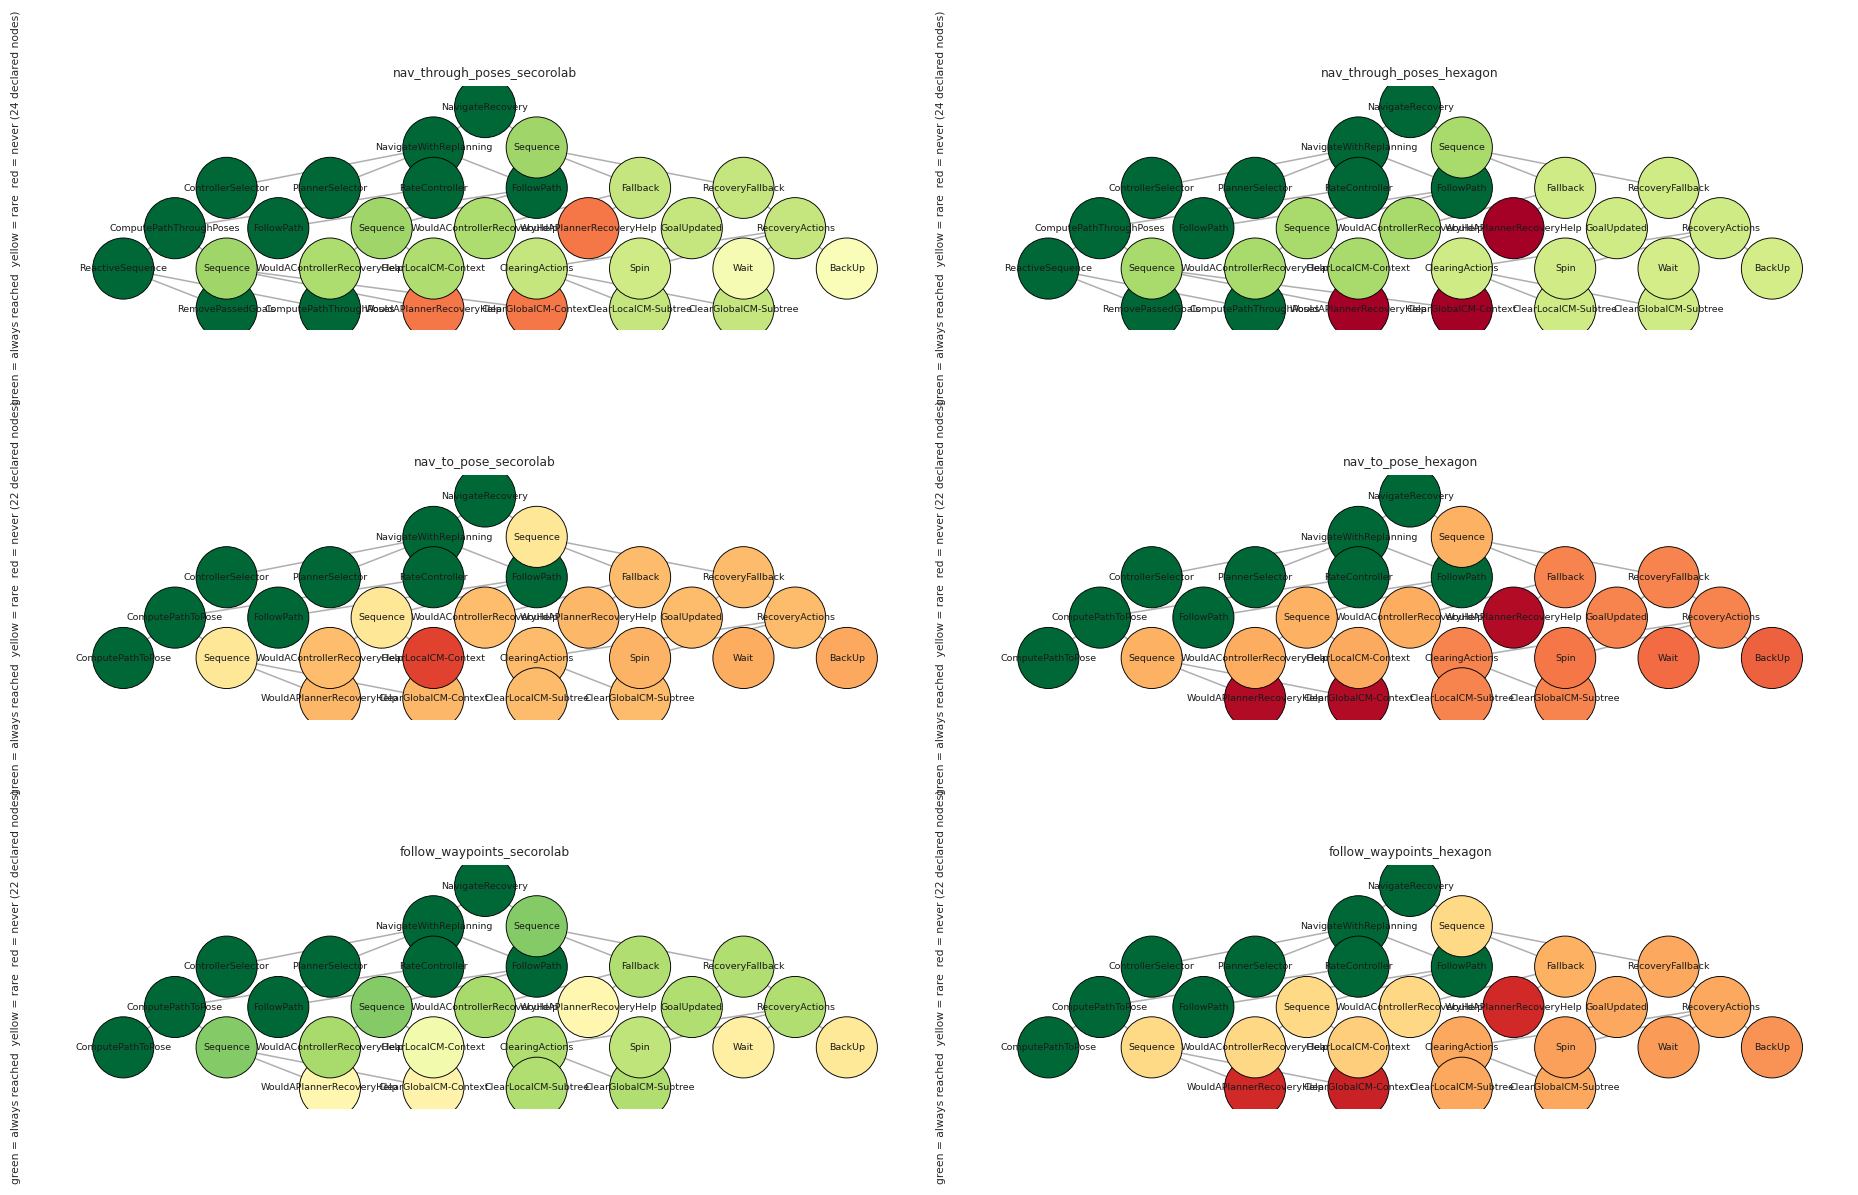

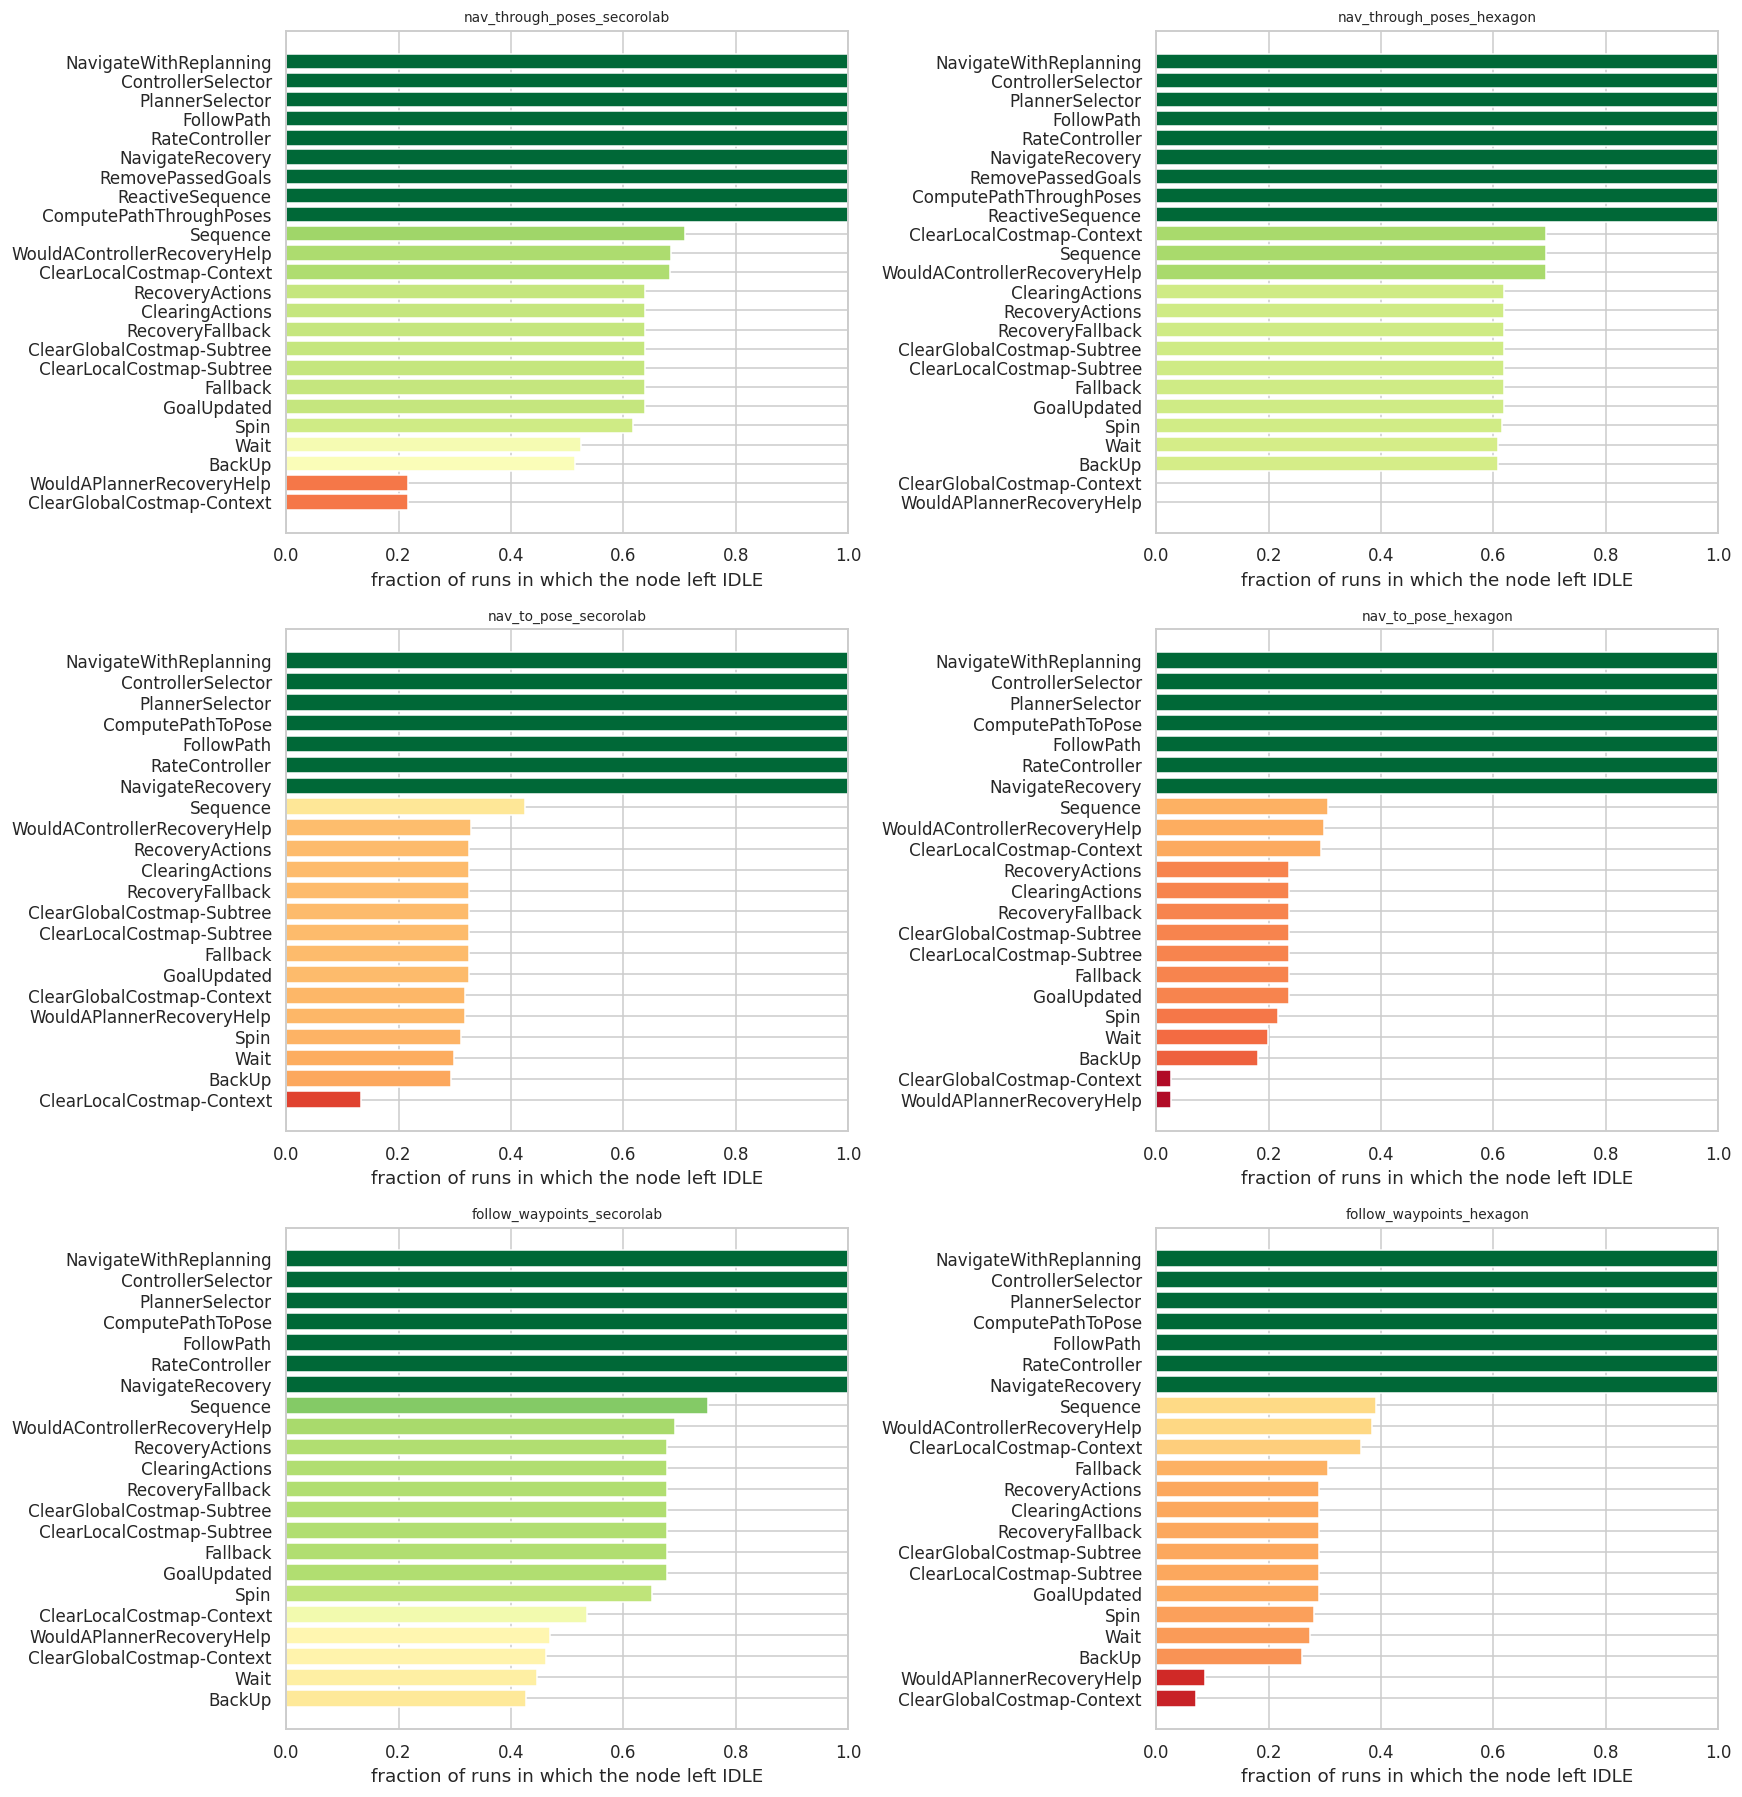

In [7]:
# fraction of runs in which each declared node left IDLE
run_fractions = {}
for n in CAMPAIGNS:
    _, reached, _ = analysis[n]
    declared = trees[n]["declared"]
    counts, total = Counter(), 0
    for rm in reached.values():
        total += 1
        for node in set(rm) & declared:
            counts[node] += 1
    run_fractions[n] = {nd: counts[nd] / total for nd in declared}

def _tree_pos(names, parents):
    children, roots = defaultdict(list), []
    for i, p in parents.items():
        (roots if p is None else children[p]).append(i)
    depth = {}
    def dfs(i, d):
        depth[i] = d
        for j in children[i]:
            dfs(j, d + 1)
    for r in roots:
        dfs(r, 0)
    layers = defaultdict(list)
    for i in range(len(names)):
        layers[depth[i]].append(i)
    pos = {}
    for d, members in layers.items():
        m = len(members)
        for k, i in enumerate(members):
            pos[i] = (k - (m - 1) / 2, -d * 1.6)
    return pos

def _draw_tree(name, ax):
    t = trees[name]
    pos = _tree_pos(t["names"], t["parents"])
    G = nx.DiGraph() if nx is not None else None
    if nx is not None:
        G.add_edges_from((p, i) for i, p in t["parents"].items() if p is not None)
    frac = run_fractions[name]
    cmap = plt.get_cmap("RdYlGn")
    colors = [cmap(frac[nm]) for nm in t["names"]]
    if nx is not None:
        nx.draw_networkx_edges(G, pos, ax=ax, alpha=0.35, arrows=True, arrowsize=7)
        nx.draw_networkx_nodes(G, pos, ax=ax, node_color=colors, node_size=1600,
                               edgecolors="black", linewidths=0.6)
        labels = {i: n_.replace("Costmap", "CM") for i, n_ in enumerate(t["names"])}
        nx.draw_networkx_labels(G, pos, labels=labels, ax=ax, font_size=6.2)
    ax.set_title(f"{name}", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)

if nx is not None:
    ncol = 2
    nrow = (len(CAMPAIGNS) + ncol - 1) // ncol
    fig, axs = plt.subplots(nrow, ncol, figsize=(17, nrow * 3.6))
    axs = np.atleast_1d(axs).ravel()
    for ax, n in zip(axs, CAMPAIGNS):
        _draw_tree(n, ax)
        ax.text(-0.03, 0.5, f"green = always reached  yellow = rare  red = never "
                            f"({len(trees[n]['declared'])} declared nodes)",
                transform=ax.transAxes, ha="right", va="center", fontsize=7, rotation=90)
    for ax in axs[len(CAMPAIGNS):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("networkx not installed; skipping tree diagrams")

ncol = 2
nrow = (len(CAMPAIGNS) + ncol - 1) // ncol
fig, axs = plt.subplots(nrow, ncol, figsize=(16, 5.5 * nrow))
axs = np.atleast_1d(axs).ravel()
for ax, n in zip(axs, CAMPAIGNS):
    s = pd.Series(run_fractions[n]).sort_values()
    ax.barh(s.index, s.values, color=plt.get_cmap("RdYlGn")(s.values))
    ax.set_xlim(0, 1)
    ax.set_title(f"{n}", fontsize=9)
    ax.set_xlabel("fraction of runs in which the node left IDLE")
for ax in axs[len(CAMPAIGNS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

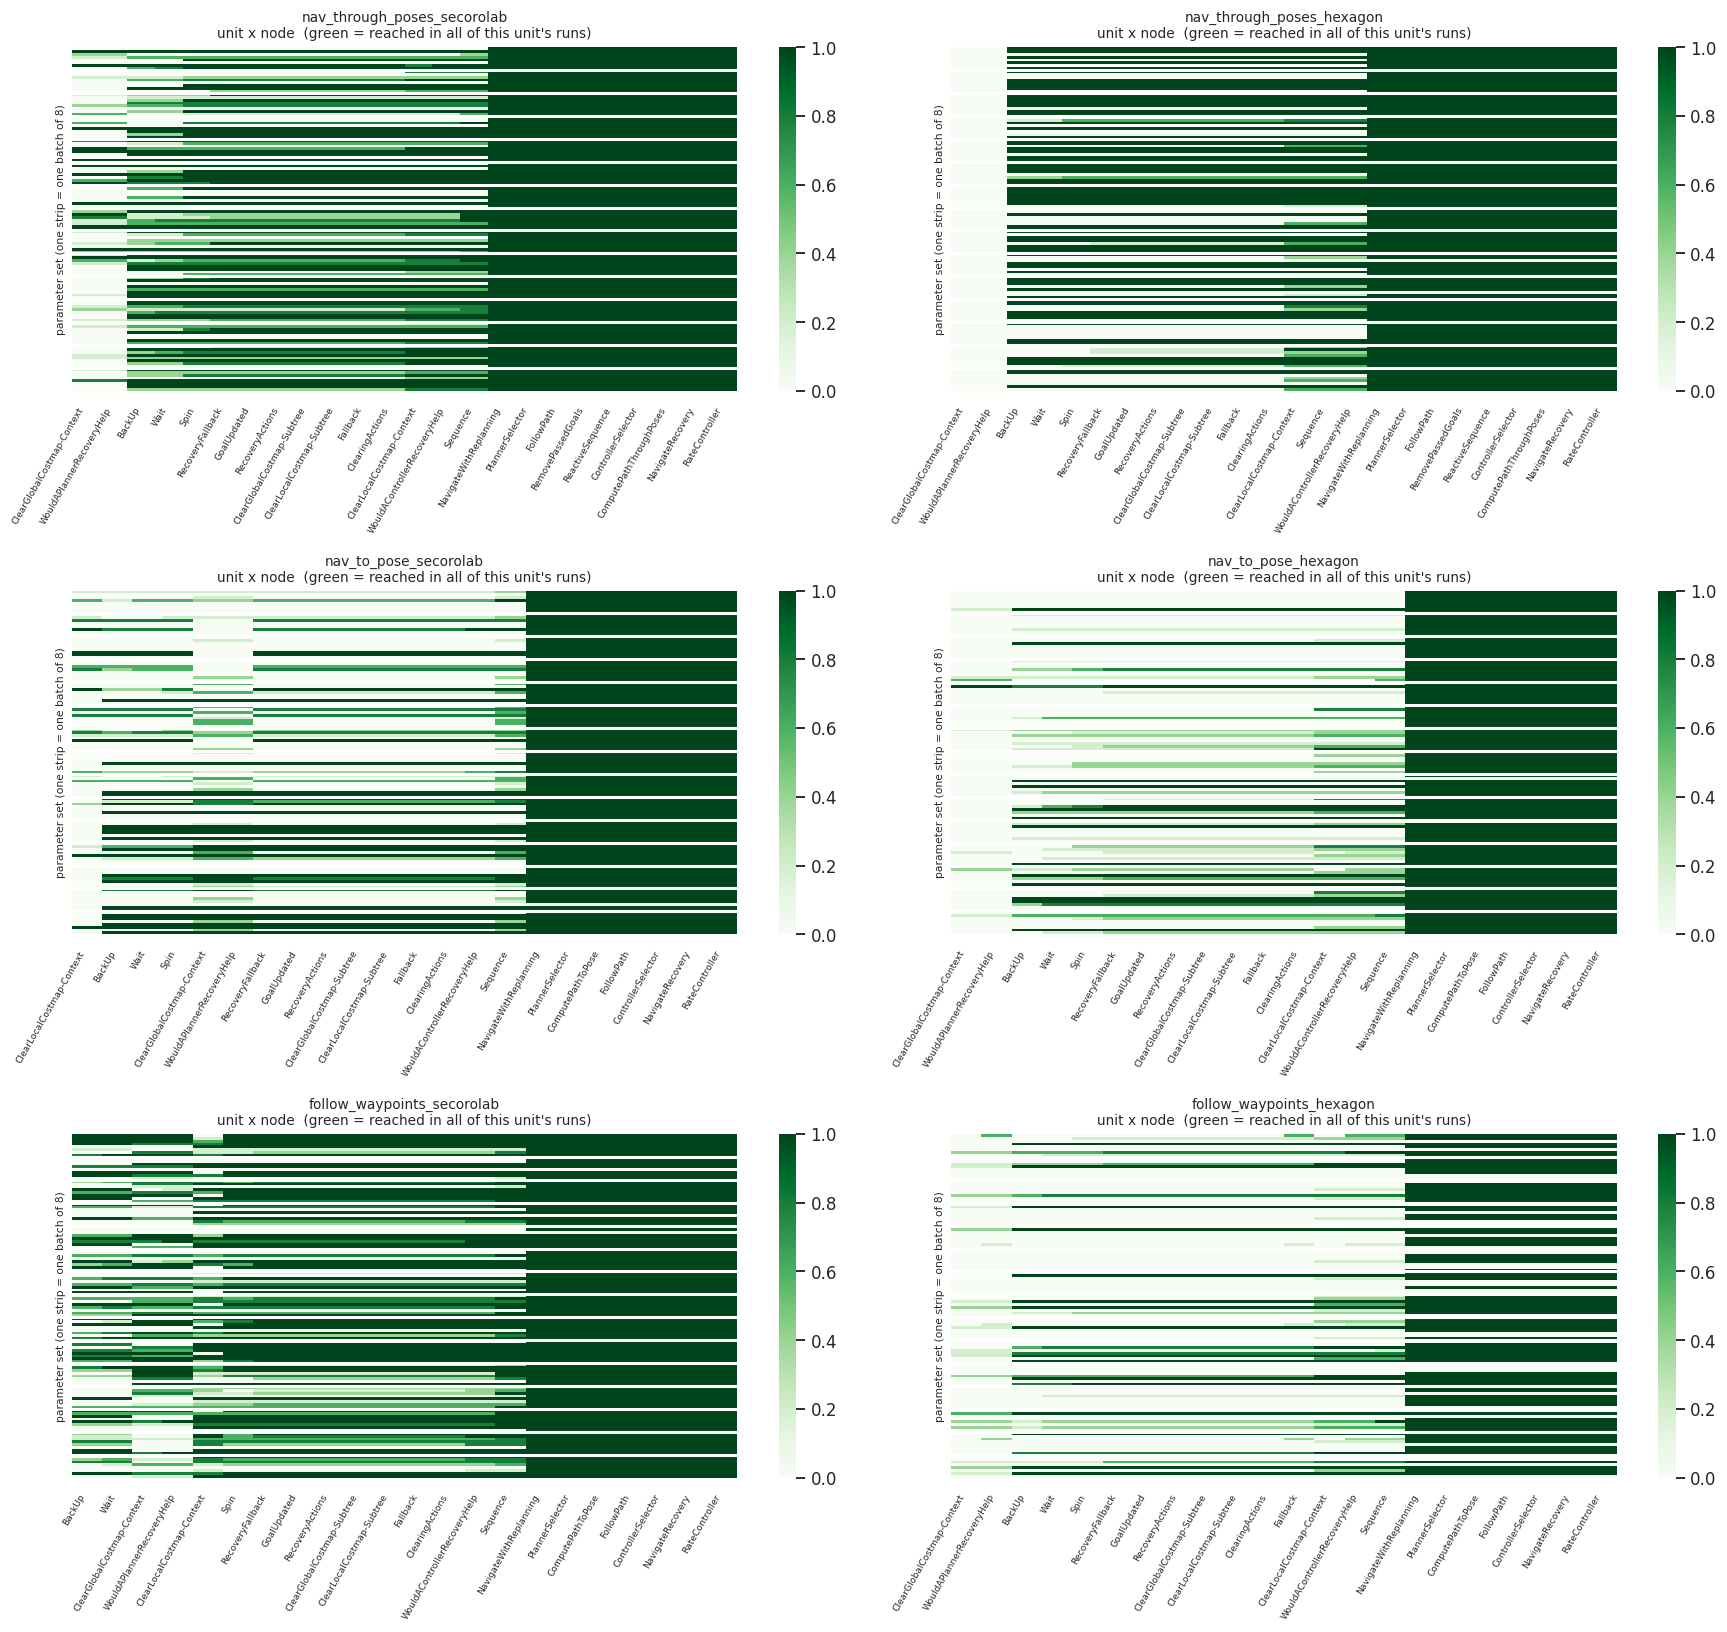

In [8]:
# per-unit x node heatmap: mean fraction of the unit's runs that reached each node
ncol = 2
nrow = (len(CAMPAIGNS) + ncol - 1) // ncol
fig, axs = plt.subplots(nrow, ncol, figsize=(16.5, 10 * nrow / 2))
axs = np.atleast_1d(axs).ravel()
for ax, n in zip(axs, CAMPAIGNS):
    _, reached, _ = analysis[n]
    units = campaigns[n]["units"].sort_values("batch").reset_index(drop=True)
    nodes = sorted(trees[n]["declared"], key=lambda x: run_fractions[n][x])
    mat = np.zeros((len(units), len(nodes)))
    for ui, (_, u) in enumerate(units.iterrows()):
        cname = u["config_name"]
        runs_of = [rm for b, rm in reached.items() if Path(b).parents[1].name == cname]
        for ni, node in enumerate(nodes):
            mat[ui, ni] = sum(node in rm for rm in runs_of) / max(len(runs_of), 1)
    sns.heatmap(mat, ax=ax, cmap="Greens", vmin=0, vmax=1, cbar=True,
                yticklabels=False, xticklabels=nodes)
    ax.set_xticklabels(nodes, rotation=60, ha="right", fontsize=6)
    batches = units["batch"].to_numpy()
    edges = [i for i in range(1, len(batches)) if batches[i] != batches[i - 1]]
    for ib in edges:
        ax.axhline(ib, color="white", lw=2.0)
    ax.set_title(f"{n}\nunit x node  (green = reached in all of this unit's runs)",
                 fontsize=9)
    ax.set_ylabel("parameter set (one strip = one batch of 8)", fontsize=7)
for ax in axs[len(CAMPAIGNS):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

Two things stand out in the heatmaps:

* the nodes separate cleanly into **always-reached core** nodes (dark-green columns) and
  **rare recovery** nodes (pale columns): a run either navigates cleanly (only the core fires)
  or trips the entire recovery chain (nearly everything fires),
* per-run coverage is therefore almost **bimodal**, which the per-batch charts confirm next.

## 5. Coverage over time (batch-by-batch)

For each campaign the figure shows: the eight per-unit coverages per batch, the batch mean, the
***best objective so far*** (running max) and, in the third panel, the **cumulative number of
distinct tree nodes** triggered by at least one run up to that batch.

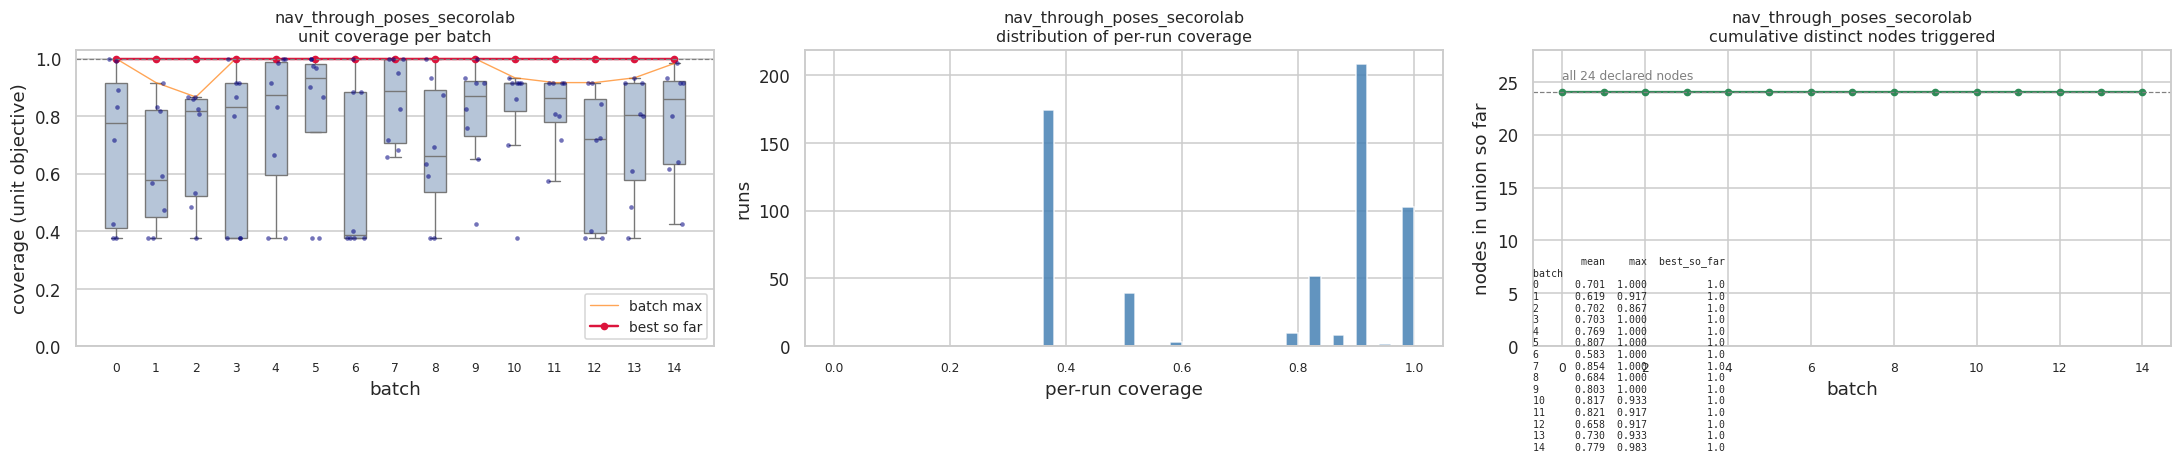

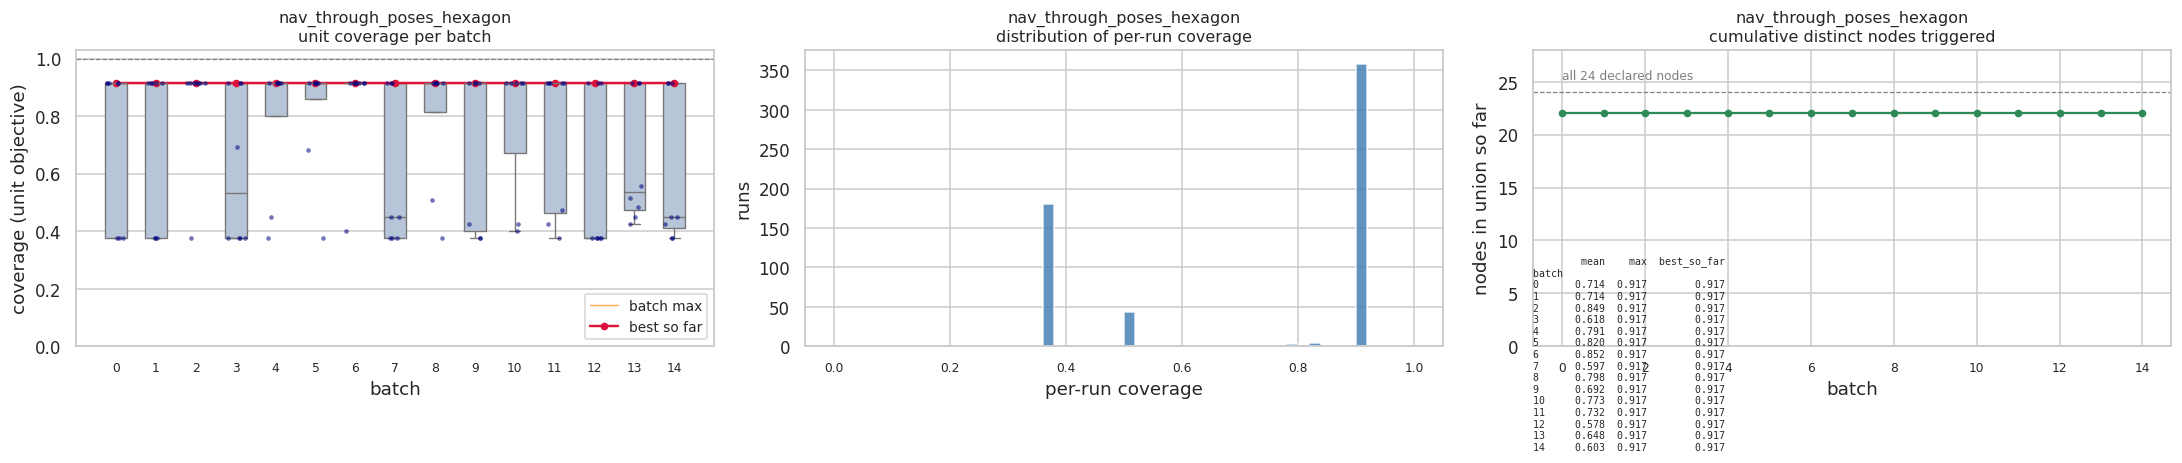

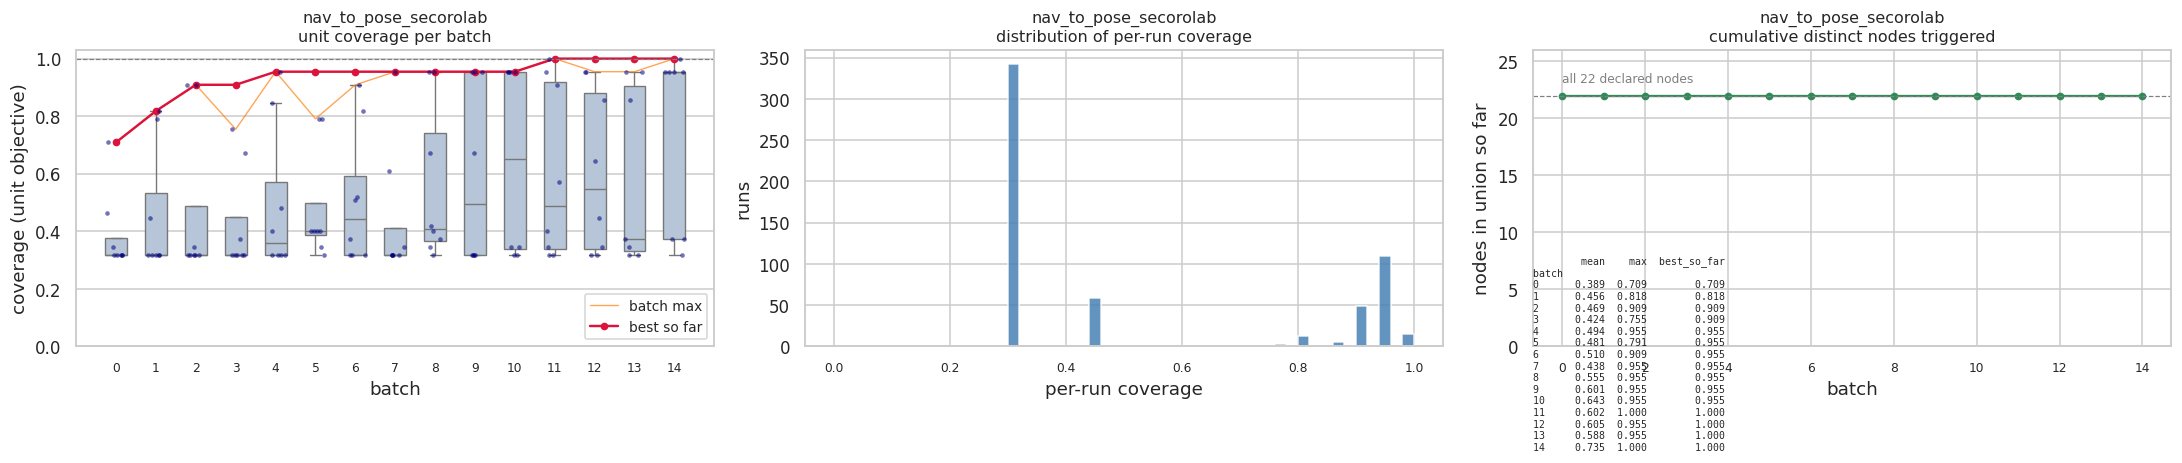

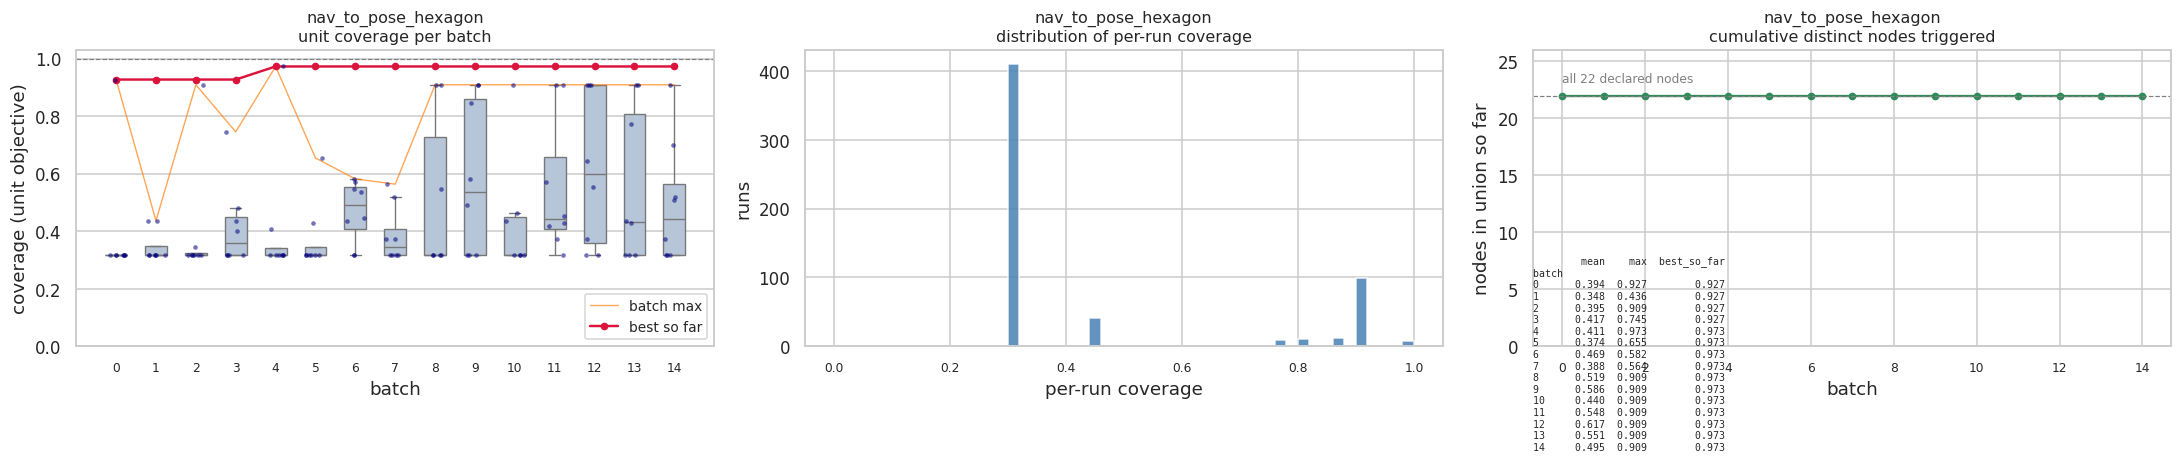

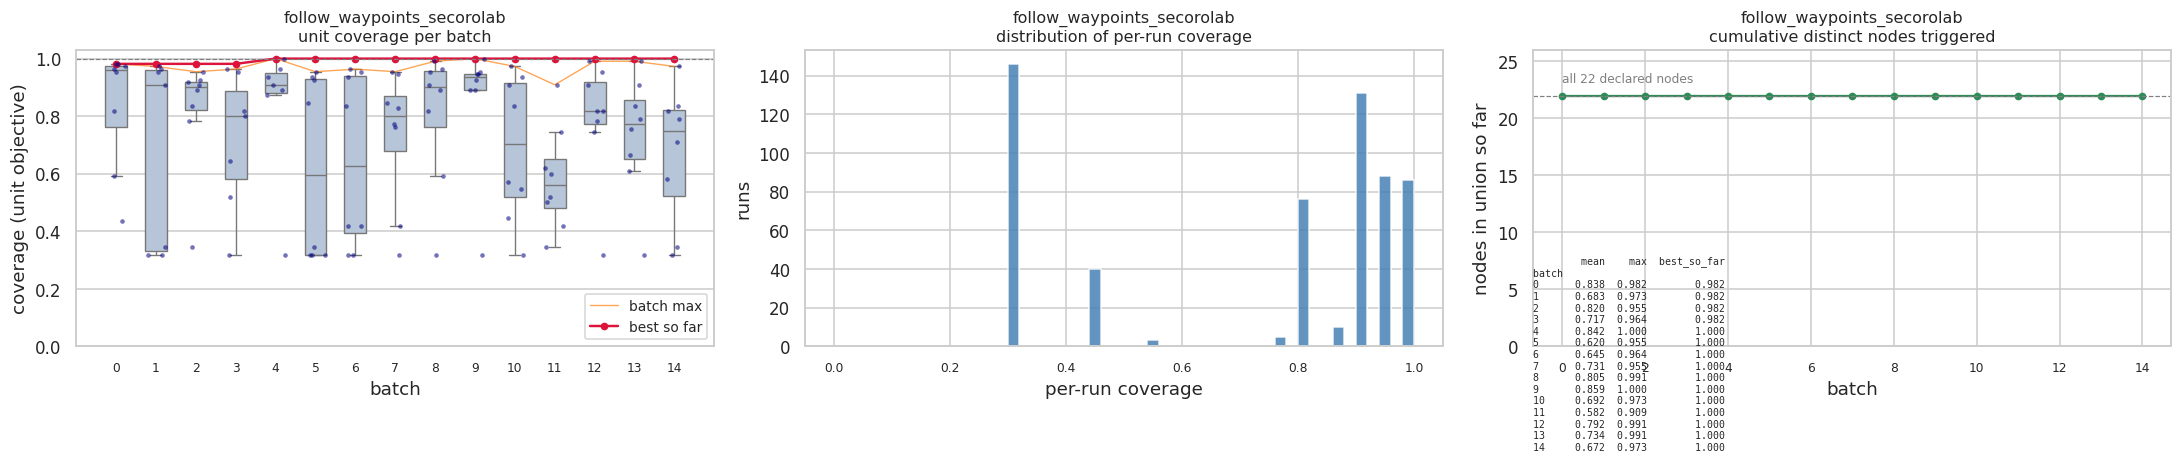

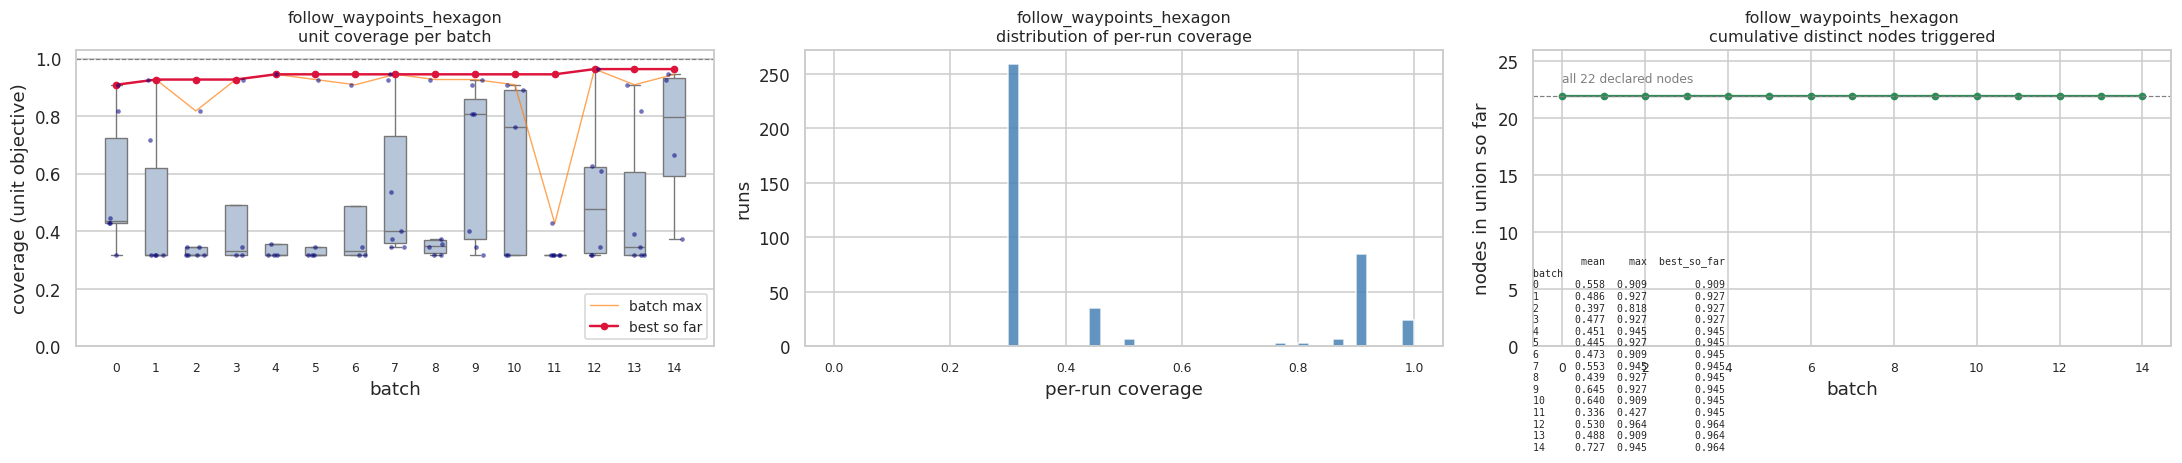

In [9]:
# Coverage over time, one figure per campaign so each panel stays readable.
def _batch_perf(u):
    return u.groupby("batch")["objective"].agg(["mean", "max"])

for n in CAMPAIGNS:
    u = campaigns[n]["units"].dropna(subset=["objective"]).copy()
    r, reached, den = analysis[n]
    perf = _batch_perf(u)
    best_so_far = perf["max"].cummax()

    fig, axs = plt.subplots(1, 3, figsize=(20, 4.7))

    ax = axs[0]
    sns.boxplot(data=u, x="batch", y="objective", ax=ax, color="lightsteelblue",
                width=0.55, showfliers=False, linewidth=0.9)
    sns.stripplot(data=u, x="batch", y="objective", ax=ax, color="navy",
                  size=3, alpha=0.55, jitter=0.24)
    ax.plot(perf.index, perf["max"].values, "-", color="tab:orange", lw=0.9,
            alpha=0.7, label="batch max")
    ax.plot(best_so_far.index, best_so_far.values, "-o", color="crimson",
            ms=4, lw=1.6, label="best so far")
    ax.axhline(1.0, ls="--", c="grey", lw=0.8)
    ax.set_ylim(0, 1.03)
    ax.set_title(f"{n}\nunit coverage per batch", fontsize=10.5)
    ax.set_xlabel("batch"); ax.set_ylabel("coverage (unit objective)")
    ax.legend(fontsize=9, loc="lower right")
    ax.tick_params(axis="x", labelsize=8)

    ax = axs[1]
    ax.hist(r["coverage"], bins=np.arange(0, 1.02, 0.02), color="steelblue", alpha=0.85)
    ax.set_title(f"{n}\ndistribution of per-run coverage", fontsize=10.5)
    ax.set_xlabel("per-run coverage"); ax.set_ylabel("runs")
    ax.tick_params(axis="x", labelsize=8)

    ax = axs[2]
    batch_of = dict(zip(zip(r["config_name"], r["run_id"]), r["batch"]))
    union, rows_cum = set(), []
    for bag, rm in reached.items():
        p = Path(bag); b = batch_of.get((p.parents[1].name, int(p.parent.name)))
        if b is None:
            continue
        union |= set(rm) & trees[n]["declared"]
        rows_cum.append((b, len(union)))
    cum = (pd.DataFrame(rows_cum, columns=["batch", "n"]).groupby("batch")["n"].max())
    ax.plot(cum.index, cum.values, "-o", color="seagreen", ms=4)
    ax.axhline(den, ls="--", c="grey", lw=0.8)
    ax.text(0.0, den + 1.2, f"all {den} declared nodes", fontsize=8, color="grey")
    ax.set_title(f"{n}\ncumulative distinct nodes triggered", fontsize=10.5)
    ax.set_xlabel("batch"); ax.set_ylabel("nodes in union so far")
    ax.set_ylim(0, den + 4)
    ax.tick_params(axis="x", labelsize=8)
    stats = perf.copy(); stats["best_so_far"] = best_so_far
    ax.text(0.0, -0.35, stats.round(3).to_string(),
            transform=ax.transAxes, fontsize=6.5, family="monospace")

    plt.tight_layout()
    plt.show()

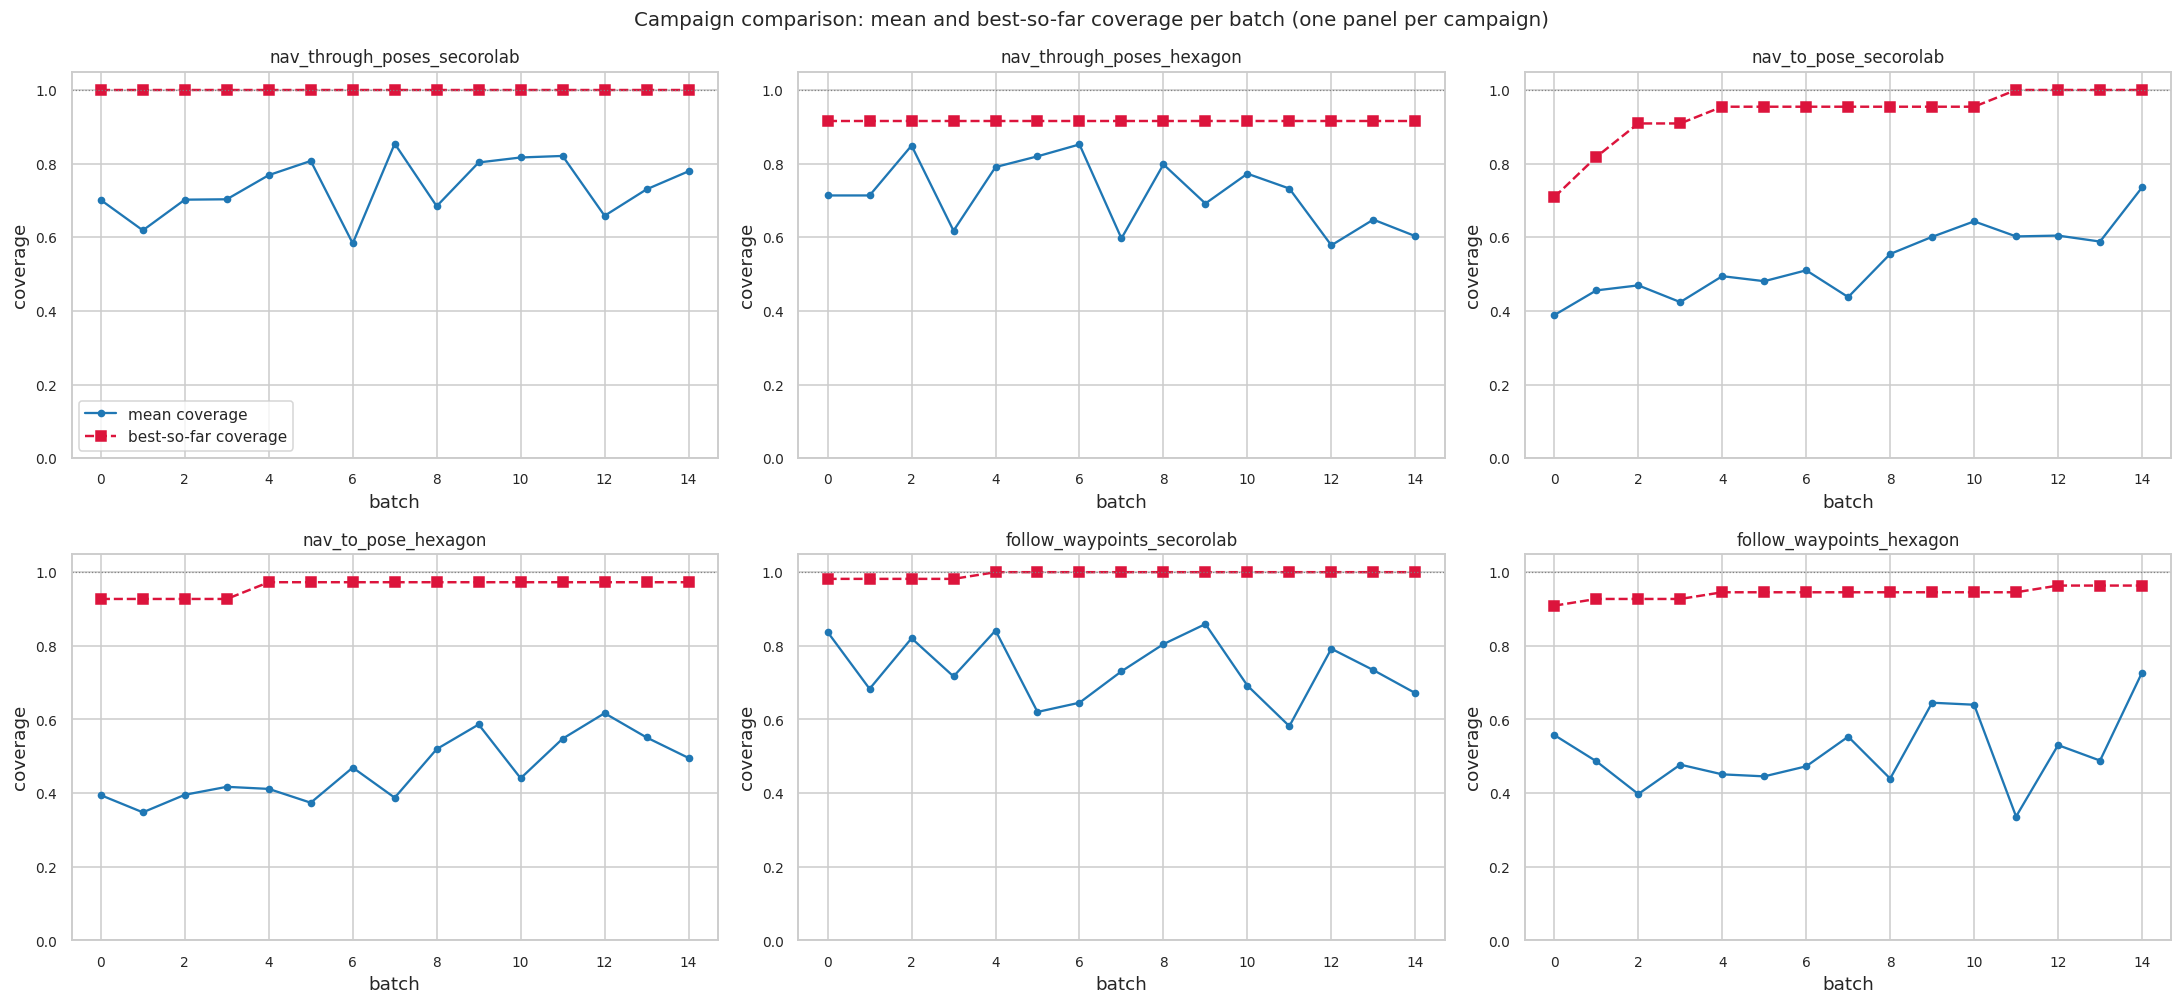

In [10]:
# Comparison across all six campaigns, as small multiples --
# one panel per campaign keeps the two series from overlapping.
fig, axs = plt.subplots(2, 3, figsize=(20, 9.3))
axs = np.atleast_2d(axs)
for k, n in enumerate(CAMPAIGNS):
    ax = axs[k // 3, k % 3]
    u = campaigns[n]["units"].dropna(subset=["objective"])
    perf = u.groupby("batch")["objective"].agg(["mean", "max"])
    ax.plot(perf.index, perf["mean"].values, marker="o", ms=4, color="tab:blue",
            label="mean coverage")
    ax.plot(perf.index, perf["max"].cummax().values, marker="s", ls="--",
            color="crimson", lw=1.6, label="best-so-far coverage")
    ax.set_title(n, fontsize=11)
    ax.set_xlabel("batch"); ax.set_ylabel("coverage")
    ax.set_ylim(0, 1.05)
    ax.axhline(1.0, ls=":", c="grey", lw=0.8)
    ax.tick_params(labelsize=9)
    if k == 0:
        ax.legend(fontsize=10)
fig.suptitle("Campaign comparison: mean and best-so-far coverage per batch "
             "(one panel per campaign)", fontsize=13)
plt.tight_layout()
plt.show()

Reading the charts:

* **secorolab** campaigns reach 100 % coverage early and keep producing 100 % cells; the
  *best-so-far* line for each hits the ceiling quickly.
* **hexagon** campaigns never reach 100 % -- their best-so-far plateaus below 1.0 (e.g.
  `nav_to_pose_hexagon` at 20/22 = 0.909), because a couple of nodes are triggered in only a few
  percent of runs.
* In every campaign the *cumulative distinct-node* count saturates long before the budget ends:
  the search spends its later batches chasing measures (archive bins), not new coverage.

## 6. Behaviour-tree nodes that were never triggered

The question has two granularities: *across the whole campaign* and *within a batch*.

In [11]:
for n in CAMPAIGNS:
    _, reached, den = analysis[n]
    union = set()
    for rm in reached.values():
        union |= set(rm) & trees[n]["declared"]
    never = sorted(trees[n]["declared"] - union)
    print(f"{n}: {len(union)}/{den} declared nodes triggered at least once across "
          f"the whole campaign")
    print(f"   NEVER triggered anywhere: {never if never else 'NONE'}")

nav_through_poses_secorolab: 24/24 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: NONE
nav_through_poses_hexagon: 22/24 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
nav_to_pose_secorolab: 22/22 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: NONE
nav_to_pose_hexagon: 22/22 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: NONE
follow_waypoints_secorolab: 22/22 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: NONE
follow_waypoints_hexagon: 22/22 declared nodes triggered at least once across the whole campaign
   NEVER triggered anywhere: NONE


In [12]:
# Within each batch: which nodes were never triggered by any run of that batch
def batch_missing(name):
    rr, reached, den = analysis[name]
    batch_of = dict(zip(zip(rr["config_name"], rr["run_id"]), rr["batch"]))
    per_batch = defaultdict(set)
    for bag, rm in reached.items():
        p = Path(bag); b = batch_of.get((p.parents[1].name, int(p.parent.name)))
        if b is not None:
            per_batch[b] |= set(rm) & trees[name]["declared"]
    return {b: sorted(trees[name]["declared"] - cov) for b, cov in sorted(per_batch.items())}

for n in CAMPAIGNS:
    missing = batch_missing(n)
    incomplete = {b: m for b, m in missing.items() if m}
    print(f"{n}: {len(incomplete)}/{len(missing)} batches left >=1 declared node untouched")
    for b, m in list(incomplete.items())[:8]:
        print(f"   batch {b:2d}: {m}")

nav_through_poses_secorolab: 0/15 batches left >=1 declared node untouched
nav_through_poses_hexagon: 15/15 batches left >=1 declared node untouched
   batch  0: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  1: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  2: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  3: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  4: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  5: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  6: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
   batch  7: ['ClearGlobalCostmap-Context', 'WouldAPlannerRecoveryHelp']
nav_to_pose_secorolab: 2/15 batches left >=1 declared node untouched
   batch 10: ['ClearLocalCostmap-Context']
   batch 13: ['ClearLocalCostmap-Context']
nav_to_pose_hexagon: 8/15 batches left >=1 declared node untouched
   batch  1: ['ClearGlobalCostmap-Context', '

Across all six campaigns **no node is left permanently uncovered** -- the union over all runs
covers the full denominator in every campaign. The "never triggered" question only bites at
batch granularity.

The bar charts below rank every declared node by how rarely it fired, so the "untriggered
node" set is really a spectrum: the interesting nodes are those a campaign triggered only a
handful of times.

In [13]:
for n in CAMPAIGNS:
    _, _, den = analysis[n]
    frac = run_fractions[n]
    s = pd.Series(frac).sort_values()
    print(f"=== {n}  (per-run reach fraction of each declared node) ===")
    for name_, f in s.items():
        bar = "#" * int(round(f * 40))
        print(f"   {name_:34s} {f:5.1%}  {bar}")
    print()

=== nav_through_poses_secorolab  (per-run reach fraction of each declared node) ===
   ClearGlobalCostmap-Context         21.7%  #########
   WouldAPlannerRecoveryHelp          21.7%  #########
   BackUp                             51.4%  #####################
   Wait                               52.4%  #####################
   Spin                               61.8%  #########################
   GoalUpdated                        63.9%  ##########################
   Fallback                           63.9%  ##########################
   ClearLocalCostmap-Subtree          63.9%  ##########################
   ClearGlobalCostmap-Subtree         63.9%  ##########################
   RecoveryFallback                   63.9%  ##########################
   ClearingActions                    63.9%  ##########################
   RecoveryActions                    63.9%  ##########################
   ClearLocalCostmap-Context          68.3%  ###########################
   WouldAControllerRecov

In [14]:
# runs that never left the 'clean navigation' baseline (no recovery node at all)
# baseline coverage = 9/den for navigate-through-poses trees, 7/den for navigate-to-pose trees
for n in CAMPAIGNS:
    r, _, _ = analysis[n]
    den = len(trees[n]["declared"])
    baseline_nodes = 9 if "through_poses" in n else 7
    baseline = r["coverage"] <= (baseline_nodes / den) + 1e-9
    print(f"{n}: {baseline.sum()} of {len(r)} runs ({baseline.mean():.1%}) stayed on the "
          f"clean-navigation baseline and never fired a single recovery node")

nav_through_poses_secorolab: 174 of 599 runs (29.0%) stayed on the clean-navigation baseline and never fired a single recovery node
nav_through_poses_hexagon: 180 of 589 runs (30.6%) stayed on the clean-navigation baseline and never fired a single recovery node
nav_to_pose_secorolab: 342 of 595 runs (57.5%) stayed on the clean-navigation baseline and never fired a single recovery node
nav_to_pose_hexagon: 410 of 590 runs (69.5%) stayed on the clean-navigation baseline and never fired a single recovery node
follow_waypoints_secorolab: 146 of 585 runs (25.0%) stayed on the clean-navigation baseline and never fired a single recovery node
follow_waypoints_hexagon: 259 of 425 runs (60.9%) stayed on the clean-navigation baseline and never fired a single recovery node


## 7. Is the coverage metric sound?

Three checks confirm the numbers are *real* -- and one reveals an analysis trap.

**Check 1 -- the logs really contain what the extractor claims.** Every bag's node names match
the XML (no drift): `set(all logged names) == declared`, in every campaign.

**Check 2 -- `campaign.db`'s objectives equal the mean of the bag-derived per-run coverage**
(exact, shown above).

**Check 3 -- what a node needs to count as "covered".** Let's look at the *statuses* recorded
for each node in the 100 % run. `FAILURE` counts as coverage:

In [15]:
def statuses(bag_dir):
    out = defaultdict(set)
    with AnyReader([bag_dir]) as reader:
        for conn, _ts, raw in reader.messages(
                connections=[c for c in reader.connections if c.topic == "/behavior_tree_log"]):
            msg = reader.deserialize(raw, conn.msgtype)
            for ev in msg.event_log:
                if ev.current_status and ev.current_status != "IDLE":
                    out[ev.node_name].add(ev.current_status)
    return out

sec = campaigns["nav_through_poses_secorolab"]
st = statuses(sec["root"] / "cc44cd1b1a6e1-1-1-1-1-1-1-1-1-1" / "0" / "rosbag2")
interesting = ["GoalUpdated", "WouldAControllerRecoveryHelp", "Spin", "Wait", "BackUp",
               "NavigateRecovery", "FollowPath"]
print("node                    statuses observed in the '100%' run")
for nn in interesting:
    print(f"{nn:26s} {sorted(st.get(nn, []))}")

node                    statuses observed in the '100%' run
GoalUpdated                ['FAILURE']
WouldAControllerRecoveryHelp ['FAILURE', 'SUCCESS']
Spin                       ['RUNNING', 'SUCCESS']
Wait                       ['RUNNING', 'SUCCESS']
BackUp                     ['RUNNING', 'SUCCESS']
NavigateRecovery           ['RUNNING']
FollowPath                 ['FAILURE', 'RUNNING']


`GoalUpdated` only ever returned `FAILURE` (meaning *no goal update arrived*), and the two
`WouldA*RecoveryHelp` guards returned `FAILURE` too ("no recovery available") -- all three still
count as *covered*. So this metric is really **"did the node ever get ticked to a non-IDLE
status"**, i.e. breadth of code touched, with success and failure treated identically. As a
search objective for "how well did the run test the system", that is questionable: **the way to
score 100 % is to fail navigation once and run the full recovery playbook.**

**The trap -- `nav2_behaviors.csv` is NOT coverage-safe.** The web-UI artifact
`nav2_behaviors.csv` (produced by the `nav2_bt_tree` postprocessor) writes a *baseline row for
every XML node* with status `1/INVALID` "so nodes that never transition still render as grey".
Reading coverage from that CSV (e.g. counting `status_name != IDLE` rows) therefore reports
**all nodes as covered even for a run whose bag only exercised the core nodes**:

In [16]:
# the CSV artifact vs the raw bag, for the SAME low-coverage run
cfg = sec["root"] / "c2c2de7dbf25f-1-1-1-1-1-1-1-1-1" / "0"
csv_df = pd.read_csv(cfg / "nav2_behaviors.csv")
csv_names = set(csv_df[csv_df["status_name"] != "IDLE"]["behavior_name"])
bag_names = set(bag_reached(cfg / "rosbag2")) & trees["nav_through_poses_secorolab"]["declared"]
print(f"nav2_behaviors.csv -> {len(csv_names)} nodes 'covered'  ({sorted(csv_names)})")
print(f"raw bag           -> {len(bag_names)} nodes covered     ({sorted(bag_names)})")
print("status_name values seen in the CSV:", csv_df["status_name"].value_counts().to_dict())

nav2_behaviors.csv -> 24 nodes 'covered'  (['BackUp', 'ClearGlobalCostmap-Context', 'ClearGlobalCostmap-Subtree', 'ClearLocalCostmap-Context', 'ClearLocalCostmap-Subtree', 'ClearingActions', 'ComputePathThroughPoses', 'ControllerSelector', 'Fallback', 'FollowPath', 'GoalUpdated', 'NavigateRecovery', 'NavigateWithReplanning', 'PlannerSelector', 'RateController', 'ReactiveSequence', 'RecoveryActions', 'RecoveryFallback', 'RemovePassedGoals', 'Sequence', 'Spin', 'Wait', 'WouldAControllerRecoveryHelp', 'WouldAPlannerRecoveryHelp'])
raw bag           -> 9 nodes covered     (['ComputePathThroughPoses', 'ControllerSelector', 'FollowPath', 'NavigateRecovery', 'NavigateWithReplanning', 'PlannerSelector', 'RateController', 'ReactiveSequence', 'RemovePassedGoals'])
status_name values seen in the CSV: {'INVALID': 45, 'SUCCESS': 17, 'RUNNING': 13}


So: any coverage number derived from the **CSV by counting every non-IDLE row** over-reports
badly; the numbers in `campaign.db` come from the **raw bag** and are the trustworthy ones (they
match our re-derivation). The exact same caveat matters when we turn to the system tests below --
there we *do* use `nav2_behaviors.csv`, but only its **non-`INVALID`** rows, which are the ones
that actually transitioned.

## 8. Conclusion

* **The 100 % values are genuine.** The extractor reads the raw `/behavior_tree_log` bags; we
  re-derived every per-run value from those same bags and reproduced `campaign.db`'s objectives
  to floating-point precision in all six campaigns. There is no data bug inflating them.
* **But the metric is weak.** It counts *"node name ever left IDLE"* with success and failure
  treated the same, and the denominator is distinct node **names** (repeated nodes like the
  multiple `Sequence`s collapse). Reaching 100 % requires triggering the recovery subtree once --
  i.e. **getting the robot stuck**.
* **Which nodes were covered:** in every campaign the handful of core navigation nodes fired in
  100 % of runs; the remaining nodes are recovery-only and fire in a small fraction of runs
  (the exact fraction varies by campaign and world).
* **Never triggered:** at campaign level **no node is uncovered** in any campaign; the
  "untriggered node" question only bites at batch granularity (most clearly for the hexagon
  campaigns, where the planner-recovery pair is untouched in most batches).
* **Beware the CSV:** `nav2_behaviors.csv` contains an `INVALID` baseline row for *every* node,
  so counting non-IDLE CSV rows makes every run look ~100 % covered. Use the raw bags (or
  `campaign.db`), or filter to non-`INVALID` rows only.

### Suggested follow-ups

* Tally coverage as **success-weighted** (node must have returned `SUCCESS`) or by branch paths,
  so a stuck+recovering robot no longer scores 100 %.
* Add a **task-success** companion objective (goal reached, planner succeeded) so 100 % BT
  coverage is not rewarded when navigation failed completely.
* For these campaigns, the optimizer was effectively optimizing *"cause a navigation failure"* --
  consider shaping the objective (coverage only counts if the run also reached the goal) or
  treating recovery coverage as a separate measure axis.

---

# 9. Behaviour coverage of the combined nav2 system tests

The QD campaigns above *search* for BT coverage. The **nav2 system tests** (`nav2_system_tests/`)
are a separate, hand-written suite of 17 campaigns of TurtleBot4 navigation tests run with the
same RoboVAST + roqsim + Nav2 stack. We now ask the same question for the *whole suite*: which
nav2 **behaviours** do the combined system tests actually exercise?

Two complications make this different from the QD audit:

1. **Some tests do not use the behaviour tree.** `behaviors/*` (`spin`, `wait`,
   `drive_on_heading`) and `error_codes/*` call the behaviour servers `/spin`, `/wait`,
   `/drive_on_heading`, `/follow_path`, `/compute_path_to_pose`, `/compute_path_through_poses`,
   `/smooth_path` **directly** with `action_call` (they never tick a `NavigateToPose` /
   `NavigateThroughPoses` tree). They still count: a behaviour that is (also) a BT node is
   exercised by those tests even though it never went through the tree.
2. **Some tests fail *by design*.** `test-failure-navigator`, `test-waypoint-follower-stop-on-failure`,
   `test-behavior-tree-node`'s `bt-all-failure` cell and the costmap/behaviour negative cells
   intentionally abort or fail. The DB `passed` flag is therefore *not* a reliable proxy for
   "did the behaviour run". We read the per-run **`nav2_behaviors.csv` / `behaviors.jsonl` logs**
   (not the DB) to see which nodes actually transitioned, so failed-by-design runs still
   contribute their coverage.

**The behaviour universe (denominator, 27).** The system tests drive three kinds of BT:
`NavigateToPose` (the `navigate_to_pose_w_replanning_and_recovery.xml`, 22 distinct nodes),
`NavigateThroughPoses` (`navigate_through_poses_w_replanning_and_recovery.xml`, 24 distinct
nodes), and `FollowWaypoints` (which re-uses the to-pose tree leg by leg). We also include the
two behaviours that are only reachable by calling the behaviour server directly and never appear
in those two trees: `DriveOnHeading` and `SmoothPath`. The union is the 27 behaviours below.

In [17]:
SYSTEM_ROOT = DATA_ROOT / "nav2_system_tests"

def _sys_campaigns():
    for cat in sorted(p for p in SYSTEM_ROOT.iterdir() if p.is_dir()):
        for camp in sorted(p for p in cat.iterdir() if p.is_dir()):
            yield camp.name, camp

# the two BT trees the system tests actually run
to_pose_sys_xml = SYSTEM_ROOT / "system" / "test-bt-navigator-2026-09-06-10075304" \
                  / "_config" / "files" / "navigate_to_pose_w_replanning_and_recovery.xml"
thru_sys_xml = SYSTEM_ROOT / "system" / "test-nav-through-poses-2026-09-06-10461058" \
               / "_config" / "files" / "navigate_through_poses_w_replanning_and_recovery.xml"
decl_to_pose = parse_bt_xml(to_pose_sys_xml)["names"]
decl_thru = parse_bt_xml(thru_sys_xml)["names"]

# behaviours only reachable by calling the behaviour server directly
DIRECT_ONLY = {"DriveOnHeading", "SmoothPath"}

UNIVERSE = set(decl_to_pose) | set(decl_thru) | DIRECT_ONLY
print(f"behaviour universe (denominator) = {len(UNIVERSE)} behaviours")
print("  from navigate_to_pose tree      :", len(decl_to_pose), "elements /", len(set(decl_to_pose)), "distinct names")
print("  from navigate_through_poses tree:", len(decl_thru), "elements /", len(set(decl_thru)), "distinct names")
print("  direct-only (DriveOnHeading, SmoothPath):", sorted(DIRECT_ONLY))

behaviour universe (denominator) = 27 behaviours
  from navigate_to_pose tree      : 28 elements / 22 distinct names
  from navigate_through_poses tree: 30 elements / 24 distinct names
  direct-only (DriveOnHeading, SmoothPath): ['DriveOnHeading', 'SmoothPath']


In [18]:
# Which system-test campaign reaches which behaviour by DIRECT behaviour-server call.
# (These tests never tick the BT, so there is no nav2_behaviors.csv; the behaviour is inferred
#  from the action server the scenario calls -- see each *_behavior.osc / error_codes.osc.)
DIRECT_MAP = {
    "test-spin-behavior-2026-09-06-15094116":                {"Spin"},
    "test-wait-behavior-2026-09-06-15015548":                {"Wait"},
    "test-drive-on-heading-behavior-2026-09-06-15242717":    {"DriveOnHeading"},
    "test-error-codes-2026-09-06-14382214":                  {"FollowPath", "ComputePathToPose",
                                                              "ComputePathThroughPoses", "SmoothPath"},
}

# Read one run's covered BT nodes from its nav2_behaviors.csv (non-INVALID rows only --
# INVALID is the postprocessor's "never transitioned" baseline, NOT a transition).
def _covered_from_csv(csv_path):
    out = set()
    with open(csv_path) as f:
        for row in csv.DictReader(f):
            if row.get("status_name", "") not in ("INVALID", "IDLE", ""):
                out.add(row["behavior_name"])
    return out

def campaign_coverage(camp_dir):
    """Return (bt_covered, direct_covered, n_bt_runs) unioned across all runs of a campaign."""
    bt_covered, n_bt_runs = set(), 0
    for csvp in camp_dir.rglob("nav2_behaviors.csv"):
        if not csvp.parent.name.isdigit():
            continue  # only per-run dirs
        n_bt_runs += 1
        bt_covered |= _covered_from_csv(csvp)
    direct = DIRECT_MAP.get(camp_dir.name, set())
    return bt_covered & UNIVERSE, direct & UNIVERSE, n_bt_runs

print("per-campaign behaviours covered (union over all runs)")
print(f"{'campaign':46s} {'bt_runs':>7s} {'covered':>6s}  direct")
print("-" * 100)
rows = []
for name, camp_dir in _sys_campaigns():
    bt, direct, n = campaign_coverage(camp_dir)
    covered = bt | direct
    rows.append({"campaign": camp_dir.name, "bt": bt, "direct": direct,
                 "covered": covered, "n_bt_runs": n, "base": name.split("-2026")[0]})
    print(f"{rows[-1]['base']:46s} {n:7d} {len(covered):4d}/{len(UNIVERSE):2d}  {sorted(direct)}")

per-campaign behaviours covered (union over all runs)
campaign                                       bt_runs covered  direct
----------------------------------------------------------------------------------------------------
test-behavior-tree-node                             10    7/27  []
test-drive-on-heading-behavior                       0    1/27  ['DriveOnHeading']
test-spin-behavior                                   0    1/27  ['Spin']
test-wait-behavior                                   0    1/27  ['Wait']
costmap-filter                                      15    7/27  []
test-error-codes                                     0    4/27  ['ComputePathThroughPoses', 'ComputePathToPose', 'FollowPath', 'SmoothPath']
test-localization                                    5    7/27  []
planning                                             5    7/27  []
test-bt-navigator                                    5    7/27  []
test-bt-navigator-with-dijkstra                      5    7/27  []
te

Combined behaviour coverage of all 17 system-test campaigns:
   14/27 behaviours exercised = 51.9%
   NOT exercised by any system test: ['BackUp', 'ClearGlobalCostmap-Context', 'ClearGlobalCostmap-Subtree', 'ClearLocalCostmap-Context', 'ClearLocalCostmap-Subtree', 'ClearingActions', 'Fallback', 'GoalUpdated', 'RecoveryActions', 'RecoveryFallback', 'Sequence', 'WouldAControllerRecoveryHelp', 'WouldAPlannerRecoveryHelp']


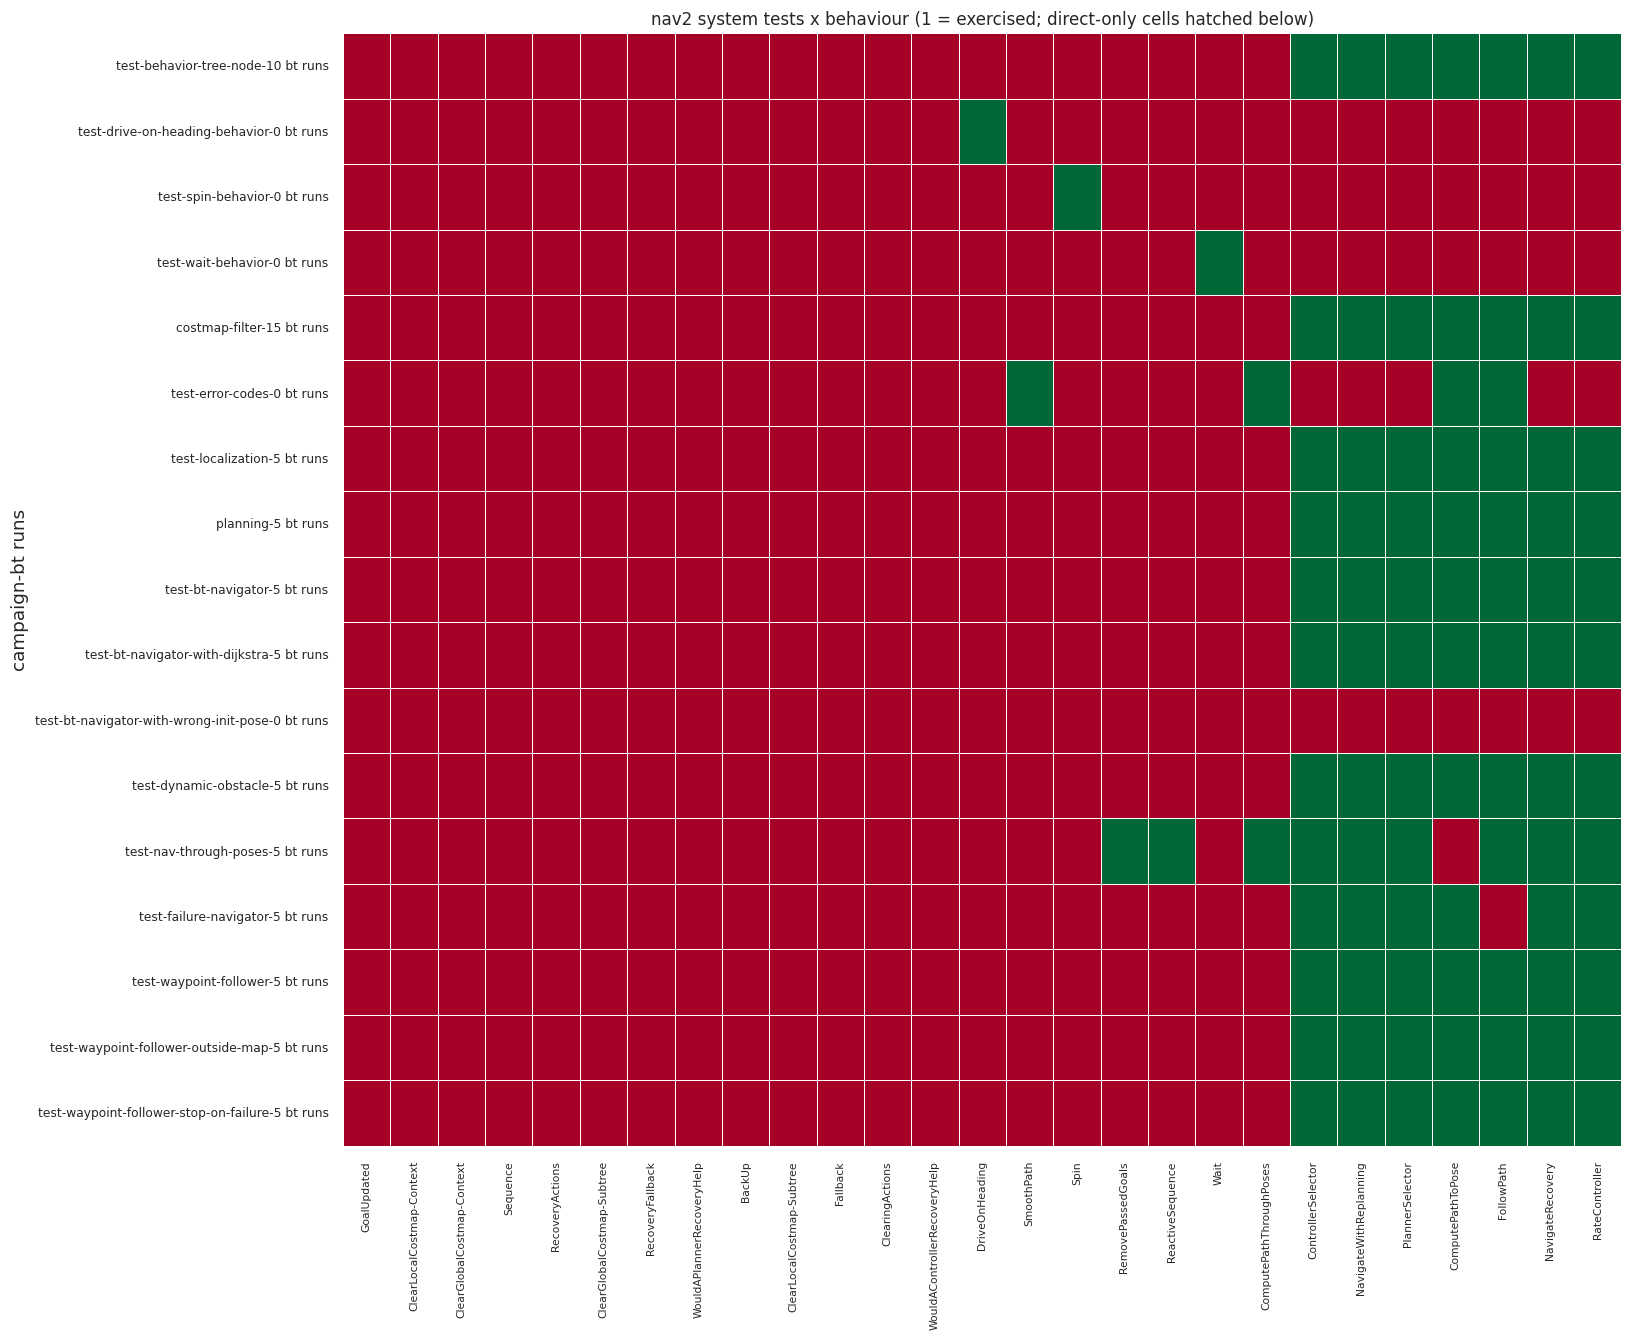

In [19]:
# Combined behaviour coverage across the whole system-test suite
combined = set()
for r in rows:
    combined |= r["covered"]
not_covered = sorted(UNIVERSE - combined)
print(f"Combined behaviour coverage of all {len(rows)} system-test campaigns:")
print(f"   {len(combined)}/{len(UNIVERSE)} behaviours exercised = {len(combined)/len(UNIVERSE):.1%}")
print(f"   NOT exercised by any system test: {not_covered}")

# A per-campaign x behaviour matrix (like the BT-node matrix, but including direct-only paths)
node_order = sorted(
    UNIVERSE,
    key=lambda b: sum(b in r["covered"] for r in rows),
)
mat = pd.DataFrame([
    {b: (1 if b in r["covered"] else 0) for b in node_order}
    for r in rows
], index=pd.MultiIndex.from_tuples([(r["base"], f"{r['n_bt_runs']} bt runs") for r in rows],
                    names=["campaign", "bt runs"]))
fig, ax = plt.subplots(figsize=(15, 0.55 * len(rows) + 3))
sns.heatmap(mat.astype(float), ax=ax, cmap="RdYlGn", vmin=0, vmax=1, cbar=False,
            linewidths=0.5, linecolor="white")
ax.tick_params(axis="y", labelsize=8)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.set_title("nav2 system tests x behaviour (1 = exercised; direct-only cells hatched below)",
             fontsize=11)
plt.tight_layout()
plt.show()

Reading the combined table:

* **Core navigation** (`NavigateRecovery`, `NavigateWithReplanning`, `ControllerSelector`,
  `PlannerSelector`, `RateController`) plus `ComputePathToPose` / `FollowPath` are exercised by
  every BT-driven campaign -- these are the "happy path" nodes always ticked.
* **Raw planner/controller actions** are further tested *directly* by `error_codes`
  (`ComputePathToPose`, `ComputePathThroughPoses`, `FollowPath`, `SmoothPath`) and by the
  `behaviors/*` campaigns (`Spin`, `Wait`, `DriveOnHeading`). So even where a behaviour never
  fires inside a tree, the suite still covers it.
* **Failure-by-design tests fill gaps.** e.g. `test-failure-navigator` (goal outside map) only
  reaches the 6 pre-`FollowPath` nodes but that is still real coverage of
  `ComputePathToPose`'s abort path. They are counted from the logs (not the DB pass flag).
* **Untouched behaviours.** The recovery subtree (`BackUp`, `Spin`-in-tree, `Wait`-in-tree,
  `Clear*Costmap`, `ClearingActions`, `RecoveryActions`, `RecoveryFallback`, `Fallback`,
  `GoalUpdated`, `Sequence`, the two `WouldA*RecoveryHelp` guards) is never entered -- the
  system tests never force a genuinely stuck navigation long enough to trigger the full
  recovery playbook, exactly the gap the QD campaigns were built to explore.

In [20]:
# Which tests cover each behaviour (contribution summary)
print("Each behaviour, and the campaigns that exercise it:")
for b in node_order:
    srcs = [r["base"] for r in rows if b in r["covered"]]
    tag = "direct-only" if b in DIRECT_ONLY else ""
    print(f"   {b:34s} {len(srcs):2d} tests   {tag}")
    print(f"       {', '.join(srcs)}")

Each behaviour, and the campaigns that exercise it:
   GoalUpdated                         0 tests   
       
   ClearLocalCostmap-Context           0 tests   
       
   ClearGlobalCostmap-Context          0 tests   
       
   Sequence                            0 tests   
       
   RecoveryActions                     0 tests   
       
   ClearGlobalCostmap-Subtree          0 tests   
       
   RecoveryFallback                    0 tests   
       
   WouldAPlannerRecoveryHelp           0 tests   
       
   BackUp                              0 tests   
       
   ClearLocalCostmap-Subtree           0 tests   
       
   Fallback                            0 tests   
       
   ClearingActions                     0 tests   
       
   WouldAControllerRecoveryHelp        0 tests   
       
   DriveOnHeading                      1 tests   direct-only
       test-drive-on-heading-behavior
   SmoothPath                          1 tests   direct-only
       test-error-codes
   Spin   

### System-test coverage: bottom line

The combined nav2 system-test suite exercises the **core navigation nodes of both trees plus the
directly-called behaviours** (`Spin`, `Wait`, `DriveOnHeading`, `FollowPath`,
`ComputePathToPose`, `ComputePathThroughPoses`, `SmoothPath`), but it **never enters the
recovery subtree** of either tree. Any behaviour-coverage claim for the suite must therefore be
stated against the 27-behaviour universe above (where the suite lands well below 100 %), and the
recovery-only behaviours are covered **only** by the QD campaigns -- a useful complementarity
between the two test families.